In [18]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from IPython.display import display

# Önceki analizdeki proje konumunu koruyoruz.
PROJECT_ROOT = Path(
    "/Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance"
)
HDF5_PATH = PROJECT_ROOT / "n_cmapss/data/N-CMAPSS_DS02-006.h5"

if not HDF5_PATH.is_file():
    raise FileNotFoundError(f"HDF5 dosyası bulunamadı: {HDF5_PATH}")


def decode_names(dataset):
    return [
        value.decode("utf-8") if isinstance(value, bytes) else str(value)
        for value in dataset[:]
    ]


with h5py.File(HDF5_PATH, mode="r") as h5:
    condition_names = decode_names(h5["W_var"])
    auxiliary_names = decode_names(h5["A_var"])

    assert "alt" in condition_names, "İrtifa değişkeni bulunamadı."
    assert {"unit", "cycle"}.issubset(auxiliary_names)
    assert h5["W_dev"].shape[0] == h5["A_dev"].shape[0]
    assert h5["W_dev"].shape[1] == len(condition_names)
    assert h5["A_dev"].shape[1] == len(auxiliary_names)

    print("Operasyonel koşullar:", condition_names)
    print("Yardımcı değişkenler:", auxiliary_names)
    print("W_dev boyutu:", h5["W_dev"].shape)
    print("A_dev boyutu:", h5["A_dev"].shape)
    print("İrtifa sütun indeksi:", condition_names.index("alt"))

    descriptions = {
        "alt": "İrtifa",
        "Mach": "Mach sayısı",
        "TRA": "Gaz kolu açısı",
        "T2": "Motor giriş toplam sıcaklığı",
    }

    display(pd.DataFrame({
        "Sütun indeksi": range(len(condition_names)),
        "Değişken": condition_names,
        "Açıklama": [
            descriptions.get(name, "Açıklama ayrıca incelenecek")
            for name in condition_names
        ],
    }))

    # Dosyada açık zaman bilgisi veya birim açıklaması var mı?
    print("\nDosya öznitelikleri:", dict(h5.attrs))
    print("W_dev öznitelikleri:", dict(h5["W_dev"].attrs))
    print("W_var öznitelikleri:", dict(h5["W_var"].attrs))
    print(
        "Adında time veya timestamp geçen kök nesneler:",
        [name for name in h5.keys()
         if "time" in name.lower() or "timestamp" in name.lower()],
    )

    # Yalnızca ilk 12 satırı okuyarak hizalamayı incele.
    sample_count = min(12, h5["W_dev"].shape[0])

    auxiliary_sample = pd.DataFrame(
        h5["A_dev"][:sample_count],
        columns=auxiliary_names,
    )
    conditions_sample = pd.DataFrame(
        h5["W_dev"][:sample_count],
        columns=condition_names,
    )

    sample = pd.concat(
        [auxiliary_sample, conditions_sample], axis=1
    )
    sample.insert(0, "hdf5_row", np.arange(sample_count))

print("\nİlk örnekler — hdf5_row zaman değil, dosyadaki satır indeksidir:")
display(sample)

Operasyonel koşullar: ['alt', 'Mach', 'TRA', 'T2']
Yardımcı değişkenler: ['unit', 'cycle', 'Fc', 'hs']
W_dev boyutu: (5263447, 4)
A_dev boyutu: (5263447, 4)
İrtifa sütun indeksi: 0


,Sütun indeksi,Değişken,Açıklama
0,0,alt,İrtifa
1,1,Mach,Mach sayısı
2,2,TRA,Gaz kolu açısı
3,3,T2,Motor giriş toplam sıcaklığı



Dosya öznitelikleri: {}
W_dev öznitelikleri: {}
W_var öznitelikleri: {}
Adında time veya timestamp geçen kök nesneler: []

İlk örnekler — hdf5_row zaman değil, dosyadaki satır indeksidir:


,hdf5_row,unit,cycle,Fc,hs,alt,Mach,TRA,T2
0,0,2.0,1.0,3.0,1.0,10005.0,0.448497,76.903748,502.420918
1,1,2.0,1.0,3.0,1.0,10013.0,0.447741,76.903748,502.326114
2,2,2.0,1.0,3.0,1.0,10017.0,0.448938,77.079529,502.416067
3,3,2.0,1.0,3.0,1.0,10024.0,0.449883,77.079529,502.469893
4,4,2.0,1.0,3.0,1.0,10031.0,0.449379,77.079529,502.401271
5,5,2.0,1.0,3.0,1.0,10040.0,0.447993,77.079529,502.248778
6,6,2.0,1.0,3.0,1.0,10044.0,0.448749,77.079529,502.297384
7,7,2.0,1.0,3.0,1.0,10048.0,0.449820,77.079529,502.376490
8,8,2.0,1.0,3.0,1.0,10056.0,0.448938,77.079529,502.269929
9,9,2.0,1.0,3.0,1.0,10059.0,0.448875,77.079529,502.254004


## Uçuş Sınırlarının Belirlenmesi

Operasyonel koşullar `alt`, `Mach`, `TRA` ve `T2` değişkenlerinden oluşur.
Uçuş evrelerini incelemek için öncelikle irtifa (`alt`) profilini kullanacağız.

İncelenen HDF5 özniteliklerinde ve kök nesne adlarında açık zaman bilgisi
bulunmadı. Bu nedenle yatay eksen örnek sırası olacaktır. Örnekleme aralığı
doğrulanmadan irtifa değişimi fiziksel dikey hız olarak yorumlanmayacaktır.

### Uçuşları nasıl ayıracağız?

`A_dev` içindeki `unit` motoru, `cycle` ise uçuşu tanımlar.
Bu iki değerden biri değiştiğinde yeni bir uçuş segmenti başlar.

Her uçuş için şu bilgiler tutulacaktır:

- Motor ve uçuş numarası
- Başlangıç satırı (`start_row`, dahil)
- Bitiş satırı (`end_row`, hariç)
- Örnek sayısı

Her motor/uçuş çiftinin tek bir kesintisiz segment oluşturduğu ve
segmentlerin bütün development satırlarını kapsadığı kontrol edilecektir.

İrtifa farkları yalnızca aynı uçuş içinde hesaplanacaktır.
Bu aşamada eşik seçilmeyecek veya uçuş evresi etiketi atanmayacaktır.

In [19]:
with h5py.File(HDF5_PATH, mode="r") as h5:
    auxiliary_names = decode_names(h5["A_var"])
    unit_index = auxiliary_names.index("unit")
    cycle_index = auxiliary_names.index("cycle")

    # Yalnızca iki kimlik sütununu oku.
    units = h5["A_dev"][:, unit_index]
    cycles = h5["A_dev"][:, cycle_index]

assert len(units) > 0
assert np.isfinite(units).all() and np.isfinite(cycles).all()
assert np.equal(units, np.floor(units)).all()
assert np.equal(cycles, np.floor(cycles)).all()

units = units.astype(np.int32)
cycles = cycles.astype(np.int32)

# Motor veya uçuş numarası değiştiğinde yeni segment başlar.
flight_changed = (
    (units[1:] != units[:-1])
    | (cycles[1:] != cycles[:-1])
)

start_rows = np.r_[0, np.flatnonzero(flight_changed) + 1]
end_rows = np.r_[start_rows[1:], len(units)]

flight_catalog = pd.DataFrame({
    "unit": units[start_rows],
    "cycle": cycles[start_rows],
    "start_row": start_rows,
    "end_row": end_rows,
})
flight_catalog["sample_count"] = (
    flight_catalog["end_row"] - flight_catalog["start_row"]
)

# Her motor/uçuş çifti dosyada tek bir kesintisiz segment olmalı.
assert not flight_catalog.duplicated(["unit", "cycle"]).any(), (
    "Bir motor/uçuş çifti birden fazla segmentte bulundu; inceleme gerekli."
)
assert flight_catalog["sample_count"].gt(0).all()
assert flight_catalog["sample_count"].sum() == len(units)

print("Toplam uçuş:", len(flight_catalog))
print("Toplam örnek:", flight_catalog["sample_count"].sum())
print("start_row dahil, end_row hariçtir.")

display(
    flight_catalog.groupby("unit").agg(
        ucus_sayisi=("cycle", "size"),
        toplam_ornek=("sample_count", "sum"),
        en_kisa_ucus_ornek=("sample_count", "min"),
        en_uzun_ucus_ornek=("sample_count", "max"),
    )
)

display(flight_catalog.head())

# Büyük geçici kimlik dizilerini serbest bırak.
del units, cycles, flight_changed, start_rows, end_rows

Toplam uçuş: 446
Toplam örnek: 5263447
start_row dahil, end_row hariçtir.


,ucus_sayisi,toplam_ornek,en_kisa_ucus_ornek,en_uzun_ucus_ornek
unit,,,,
2,75,853142,5500,18169
5,89,1033420,4311,18169
10,82,952711,4311,17892
16,63,765295,5428,17892
18,71,890719,6941,17186
20,66,768160,5500,17398


,unit,cycle,start_row,end_row,sample_count
0,2,1,0,11764,11764
1,2,2,11764,22265,10501
2,2,3,22265,33358,11093
3,2,4,33358,44081,10723
4,2,5,44081,55538,11457


## Örnek Uçuşun İrtifa Profilinin İncelenmesi

İlk inceleme için Motor 2, Uçuş 1 seçilmiştir.
Bu uçuş 11.764 örnek içerir ve HDF5 içinde `[0, 11764)` satır aralığındadır.

İki görünüm incelenecektir:

1. **İrtifa profili:** Uçuş içindeki örnek sırasına göre irtifa.
2. **Ardışık irtifa farkı:** Aynı uçuş içindeki iki ardışık ölçümün farkı:
   `Δalt[i] = alt[i] − alt[i−1]`.

Pozitif fark irtifa artışını, negatif fark irtifa azalışını gösterir.
Sıfıra yakın farklar düz uçuşla uyumlu olabilir; ancak tek bir fark
değerinden seyir evresi sonucu çıkarılmayacaktır.

Bu aşamada yumuşatma, eşik seçimi veya evre sınıflandırması yapılmayacaktır.
İrtifa farkı, zaman aralığı doğrulanmadığı için dikey hız değildir.

Bu uçuşta görülen örüntüler bütün veri setine doğrudan genellenmeyecek;
yöntem belirlenmeden önce farklı motor ve uçuşlar da incelenecektir.

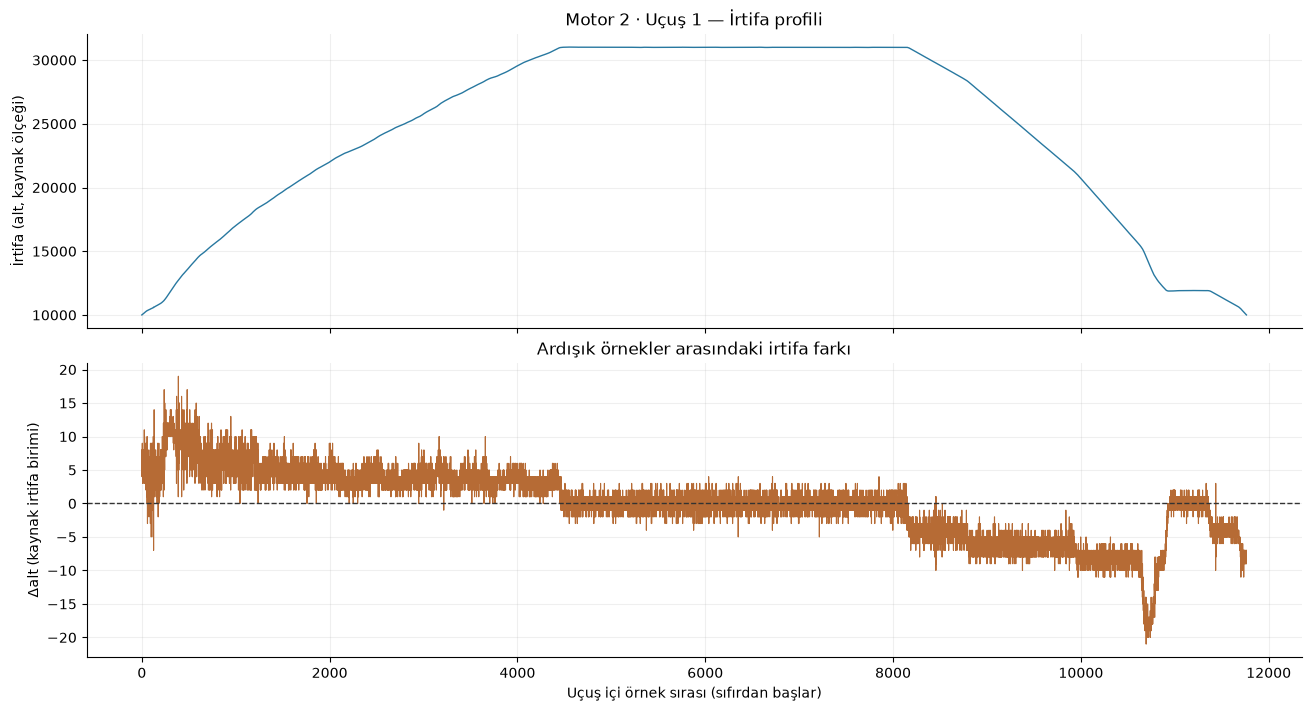

Uçuş satır aralığı: [0, 11764)
Örnek sayısı: 11,764
İrtifa minimum / maksimum: 10005.00 / 31021.00


,Ardışık irtifa farkı
count,11763.000000
mean,0.000000
std,5.021921
min,-21.000000
1%,-14.000000
5%,-8.000000
25%,-3.000000
50%,0.000000
75%,4.000000
95%,7.000000


In [20]:
import matplotlib.pyplot as plt

selected_unit = 2
selected_cycle = 1

selected_flight = flight_catalog.loc[
    flight_catalog["unit"].eq(selected_unit)
    & flight_catalog["cycle"].eq(selected_cycle)
]

assert len(selected_flight) == 1, "Tek bir uçuş segmenti bekleniyor."

flight = selected_flight.iloc[0]
start_row = int(flight["start_row"])
end_row = int(flight["end_row"])

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")
    altitude = h5["W_dev"][start_row:end_row, altitude_index]

assert len(altitude) == int(flight["sample_count"])
assert len(altitude) >= 2
assert np.isfinite(altitude).all(), "İrtifada eksik veya sonsuz değer var."

sample_index = np.arange(len(altitude))
altitude_difference = np.diff(altitude)

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 7),
    sharex=True,
    constrained_layout=True,
)

axes[0].plot(sample_index, altitude, color="#2878A0", linewidth=1)
axes[0].set(
    title=f"Motor {selected_unit} · Uçuş {selected_cycle} — İrtifa profili",
    ylabel="İrtifa (alt, kaynak ölçeği)",
)

# Fark, karşılaştırılan iki örnekten sonuncusunun konumunda gösterilir.
axes[1].plot(
    sample_index[1:],
    altitude_difference,
    color="#B66B35",
    linewidth=0.8,
)
axes[1].axhline(0, color="#333333", linestyle="--", linewidth=1)
axes[1].set(
    title="Ardışık örnekler arasındaki irtifa farkı",
    xlabel="Uçuş içi örnek sırası (sıfırdan başlar)",
    ylabel="Δalt (kaynak irtifa birimi)",
)

for ax in axes:
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

plt.show()

difference_summary = (
    pd.Series(altitude_difference, name="Ardışık irtifa farkı")
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame()
)

print(f"Uçuş satır aralığı: [{start_row}, {end_row})")
print(f"Örnek sayısı: {len(altitude):,}")
print(f"İrtifa minimum / maksimum: {altitude.min():.2f} / {altitude.max():.2f}")
display(difference_summary)

## İlk Uçuş Profilinden Çıkan Gözlemler

Motor 2, Uçuş 1’in irtifa profilinde artış, uzun bir yüksek irtifa
platosu ve azalış bölümleri görülmektedir. Alçalma sırasında kısa bir
düz bölüm de bulunmaktadır.

### Sınıflandırma açısından sonuçlar

- Ardışık irtifa farkları, düz görünen bölümlerde bile sıfır çevresinde
  dalgalanmaktadır. Tek örnek farkının işareti yeterli değildir.
- Yerel irtifa eğilimi ve bu eğilimin sürekliliği birlikte incelenmelidir.
- Sabit irtifa tek başına seyir evresini kanıtlamaz. Uçuş içindeki konum
  ve çevresindeki irtifa profili de dikkate alınmalıdır.
- Bir 256 örneklik pencere, evre geçişini kapsayabilir. Yalnızca pencerenin
  başlangıç ve bitiş irtifasına bakmak karma evreleri gizleyebilir.

Bütün uçuş boyunca ortalama irtifa farkının sıfır olması, uçuşun düz
olduğu anlamına gelmez; artış ve azalışlar toplamda birbirini dengeleyebilir.

### Sonraki inceleme

Eşik veya yumuşatma uzunluğu seçmeden önce, her motorun ilk, orta ve son
uçuşlarının irtifa profilleri karşılaştırılacaktır. Uçuş seçimi tahmin
hatasına göre yapılmayacaktır.

Bu inceleme keşif amaçlıdır. Evre tanımı tahmin hatalarını küçültecek
şekilde ayarlanmayacak; etiketleme kuralları operasyonel profillere
dayanacaktır.

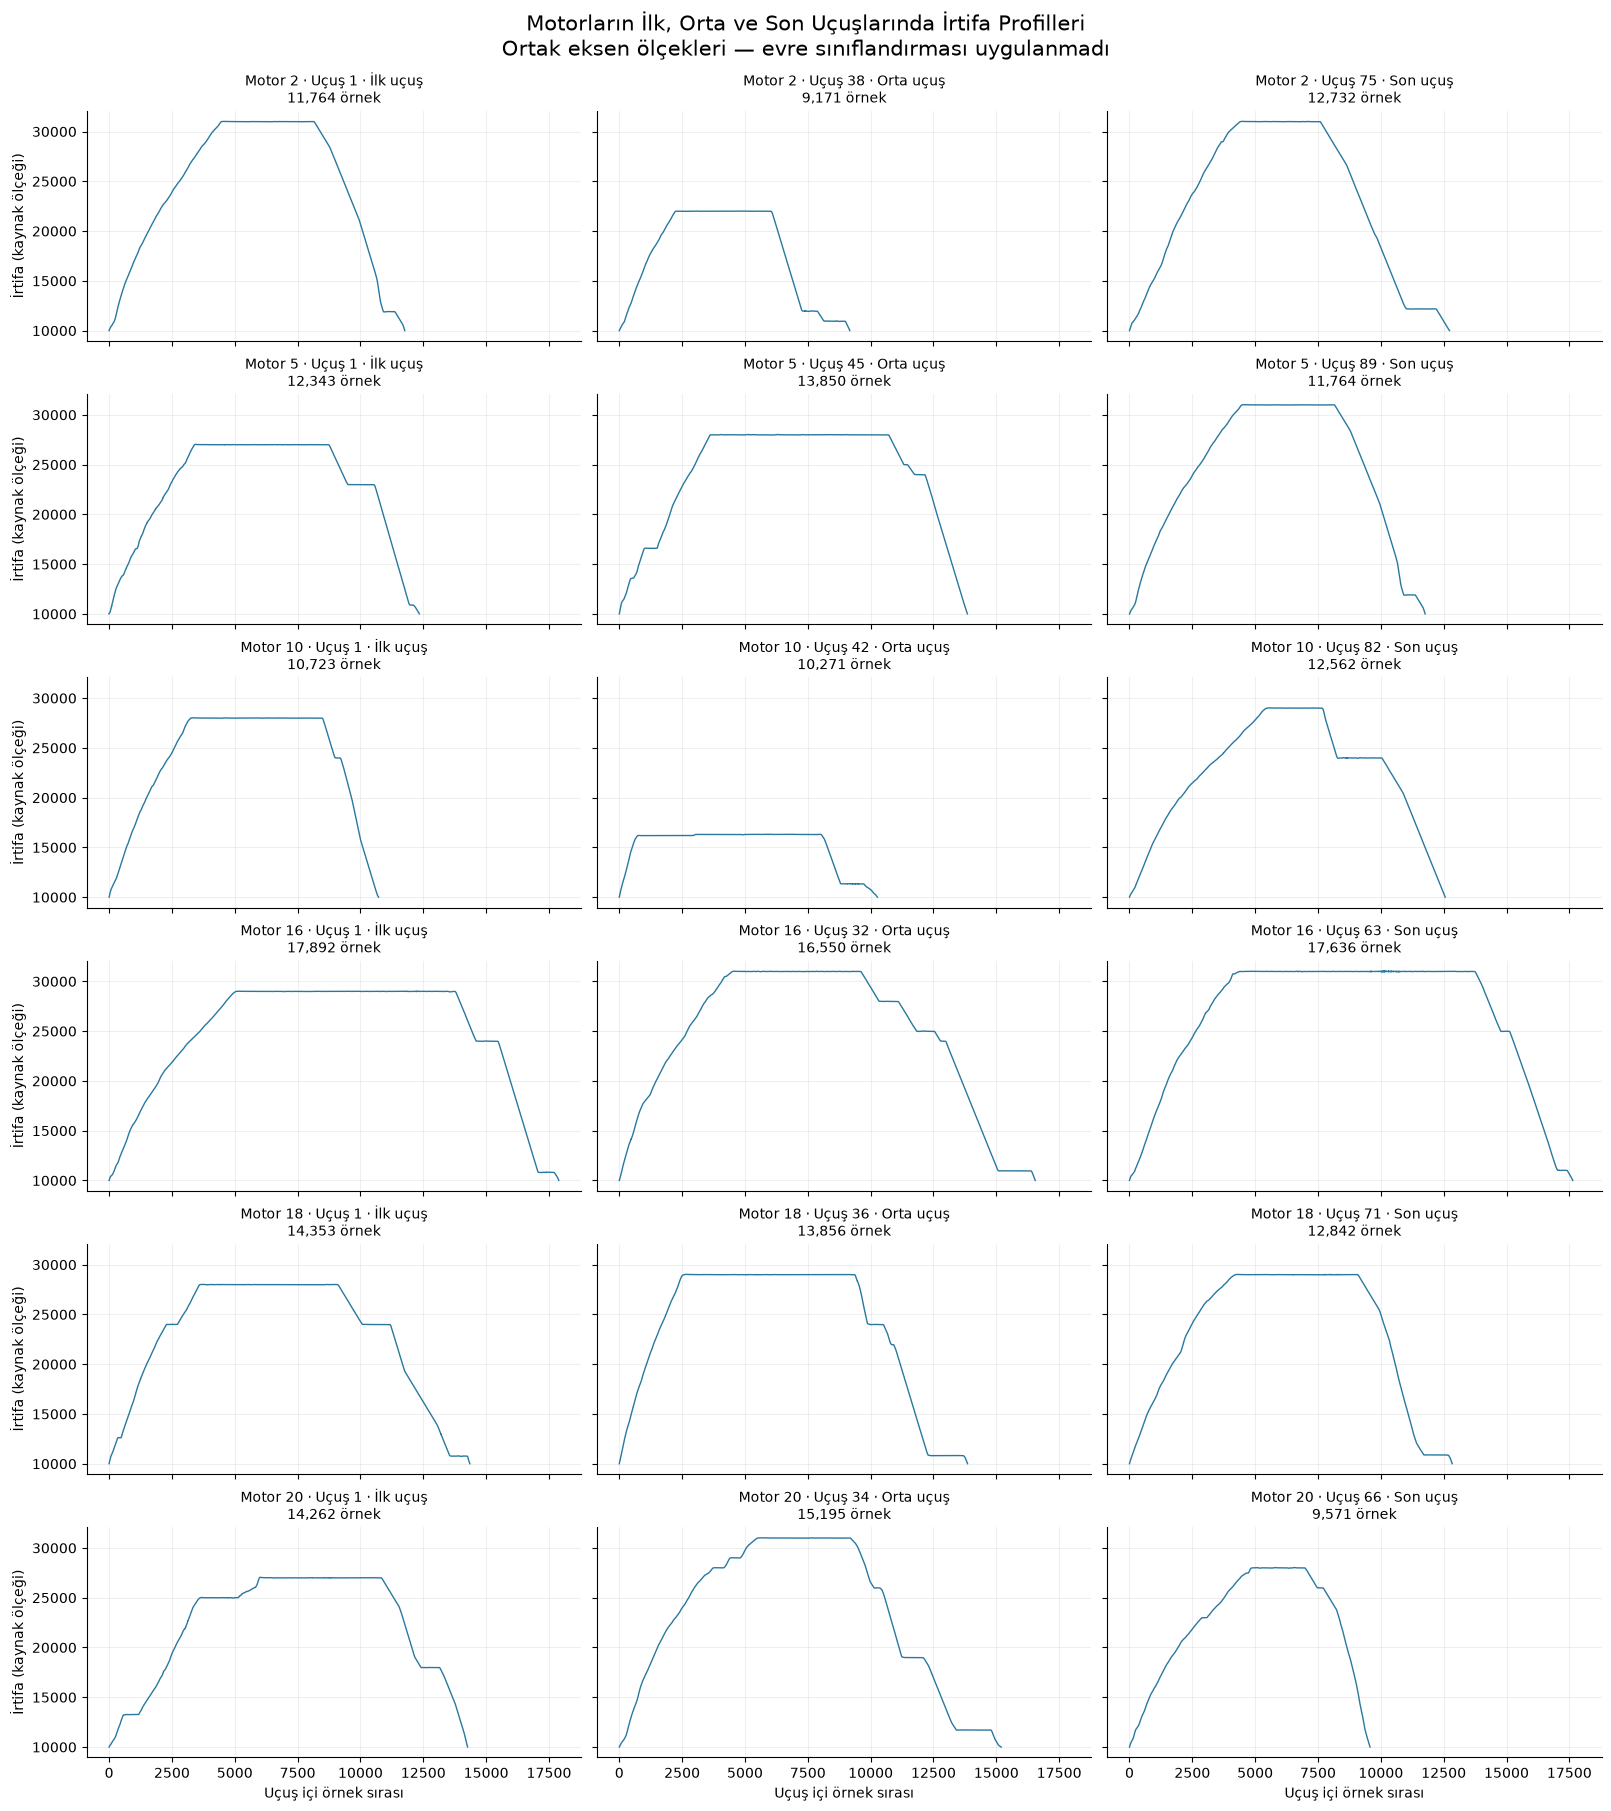

,Motor,Uçuş,Seçim,Örnek sayısı
0,2,1,İlk uçuş,11764
1,2,38,Orta uçuş,9171
2,2,75,Son uçuş,12732
3,5,1,İlk uçuş,12343
4,5,45,Orta uçuş,13850
5,5,89,Son uçuş,11764
6,10,1,İlk uçuş,10723
7,10,42,Orta uçuş,10271
8,10,82,Son uçuş,12562
9,16,1,İlk uçuş,17892


In [21]:
units_to_inspect = sorted(flight_catalog["unit"].unique())
selection_labels = ["İlk uçuş", "Orta uçuş", "Son uçuş"]
selected_records = []

for unit in units_to_inspect:
    motor_flights = (
        flight_catalog.loc[flight_catalog["unit"].eq(unit)]
        .sort_values("cycle")
        .reset_index(drop=True)
    )

    positions = [0, len(motor_flights) // 2, len(motor_flights) - 1]

    for label, position in zip(selection_labels, positions):
        record = motor_flights.iloc[position].to_dict()
        record["selection"] = label
        selected_records.append(record)

profile_selection = pd.DataFrame(selected_records)

fig, axes = plt.subplots(
    len(units_to_inspect),
    3,
    figsize=(16, 3 * len(units_to_inspect)),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")

    for ax, record in zip(
        axes.flat,
        profile_selection.to_dict("records"),
        strict=True,
    ):
        start = int(record["start_row"])
        end = int(record["end_row"])
        altitude_values = h5["W_dev"][start:end, altitude_index]

        assert len(altitude_values) == int(record["sample_count"])
        assert np.isfinite(altitude_values).all()

        ax.plot(
            np.arange(len(altitude_values)),
            altitude_values,
            color="#2878A0",
            linewidth=1,
        )
        ax.set_title(
            f"Motor {int(record['unit'])} · "
            f"Uçuş {int(record['cycle'])} · {record['selection']}\n"
            f"{len(altitude_values):,} örnek",
            fontsize=10,
        )
        ax.grid(alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("İrtifa (kaynak ölçeği)")

for ax in axes[-1, :]:
    ax.set_xlabel("Uçuş içi örnek sırası")

fig.suptitle(
    "Motorların İlk, Orta ve Son Uçuşlarında İrtifa Profilleri\n"
    "Ortak eksen ölçekleri — evre sınıflandırması uygulanmadı",
    fontsize=15,
)

plt.show()

display(
    profile_selection[
        ["unit", "cycle", "selection", "sample_count"]
    ].rename(columns={
        "unit": "Motor",
        "cycle": "Uçuş",
        "selection": "Seçim",
        "sample_count": "Örnek sayısı",
    })
)

## Farklı Uçuş Profillerinin Karşılaştırılması

İncelenen 18 uçuşta genel olarak irtifa artışı, uzun plato ve irtifa
azalışı görülmektedir. Ancak plato seviyeleri, süreleri ve ara düz
bölümler uçuşlar arasında değişmektedir.

### Yönteme etkileri

- Sabit bir mutlak irtifa eşiği bütün uçuşlara uygulanamaz.
- Tırmanış ve alçalma sırasında ara platolar bulunabilir.
  Her düz bölüm doğrudan seyir olarak etiketlenmemelidir.
- Yalnızca pencerenin başlangıç ve bitiş irtifaları, pencere içindeki
  evre değişimlerini göstermeyebilir.
- Bu 18 profil keşif örnekleridir; bütün 446 uçuşu temsil ettikleri
  varsayılmayacaktır.

### Sonraki adım: 256 örneklik pencerelerin iç yapısı

Mevcut pencere metadata’sındaki sınırlar kullanılarak her pencere için
şu irtifa özellikleri incelenecektir:

- Net irtifa değişimi: son değer − ilk değer.
- Doğrusal eğim: örnek sırasına göre genel irtifa eğilimi.
- İrtifa aralığı: maksimum − minimum.
- Pencerenin dört adet 64 örneklik bölümündeki ayrı eğimler.

64 örneklik bölümler, mevcut 256 örneklik pencerenin içindeki değişimleri
görmek için başlangıç inceleme ölçeğidir; doğrulanmış bir evre süresi
veya sınıflandırma eşiği değildir.

Bu özelliklerin dağılımları ve örnek profiller birlikte incelenecektir.
Henüz evre etiketi atanmayacak; eşikler tahmin hatalarına bakılarak
seçilmeyecektir. Belirsiz veya birden fazla evre içeren pencereleri
ayrı tutacak bir yöntem geliştirilecektir.

Bu işlem mevcut tahminlerin geriye dönük analizidir. Buradan elde
edilecek evre etiketleri model girdisi olarak kullanılmayacaktır.

In [22]:
METADATA_PATH = (
    PROJECT_ROOT / "n_cmapss/processed"
    / "window_256_stride_256/window_metadata.csv"
)
phase_metadata = pd.read_csv(METADATA_PATH)

assert phase_metadata["window_id"].is_unique
assert (
    phase_metadata["end_row"] - phase_metadata["start_row"]
).eq(256).all()

flight_lookup = flight_catalog.set_index(["unit", "cycle"])
assert flight_lookup.index.is_unique

# Doğrusal regresyon eğimi: kaynak irtifa birimi / örnek.
x256 = np.arange(256, dtype=float)
x256 -= x256.mean()

x64 = np.arange(64, dtype=float)
x64 -= x64.mean()

feature_rows = []

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")

    for (unit, cycle), windows in phase_metadata.groupby(
        ["unit", "cycle"], sort=True
    ):
        flight = flight_lookup.loc[(unit, cycle)]
        flight_start = int(flight["start_row"])
        flight_end = int(flight["end_row"])

        flight_altitude = h5["W_dev"][
            flight_start:flight_end, altitude_index
        ]
        assert np.isfinite(flight_altitude).all()

        for window in windows.itertuples(index=False):
            start = int(window.start_row)
            end = int(window.end_row)

            assert flight_start <= start < end <= flight_end, (
                f"Pencere {window.window_id}: uçuş sınırları dışında."
            )

            altitude_window = flight_altitude[
                start - flight_start:end - flight_start
            ].astype(float, copy=False)

            assert len(altitude_window) == 256

            quarter_slopes = (
                altitude_window.reshape(4, 64) @ x64
            ) / (x64 @ x64)

            feature_rows.append({
                "window_id": int(window.window_id),
                "unit": int(unit),
                "cycle": int(cycle),
                "start_row": start,
                "end_row": end,
                "alt_net_change": (
                    altitude_window[-1] - altitude_window[0]
                ),
                "alt_slope": (altitude_window @ x256) / (x256 @ x256),
                "alt_range": np.ptp(altitude_window),
                **{
                    f"alt_slope_q{i + 1}": slope
                    for i, slope in enumerate(quarter_slopes)
                },
            })

altitude_features = (
    pd.DataFrame(feature_rows)
    .sort_values("window_id")
    .reset_index(drop=True)
)
del feature_rows

feature_columns = [
    "alt_net_change",
    "alt_slope",
    "alt_range",
    "alt_slope_q1",
    "alt_slope_q2",
    "alt_slope_q3",
    "alt_slope_q4",
]

assert altitude_features["window_id"].is_unique
assert set(altitude_features["window_id"]) == set(
    phase_metadata["window_id"]
)
assert np.isfinite(altitude_features[feature_columns]).all().all()

print("İncelenen pencere sayısı:", len(altitude_features))
print(
    "İncelenen uçuş sayısı:",
    altitude_features[["unit", "cycle"]].drop_duplicates().shape[0],
)
print("Eğim birimi: kaynak irtifa birimi / örnek; dikey hız değildir.")

display(altitude_features.head())

display(
    altitude_features[feature_columns]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .round(4)
)

İncelenen pencere sayısı: 20339
İncelenen uçuş sayısı: 446
Eğim birimi: kaynak irtifa birimi / örnek; dikey hız değildir.


,window_id,unit,cycle,start_row,end_row,alt_net_change,alt_slope,alt_range,alt_slope_q1,alt_slope_q2,alt_slope_q3,alt_slope_q4
0,0,2,1,0,256,1304.0,4.501397,1304.0,5.900160,3.659592,4.101900,6.931777
1,1,2,1,256,512,2478.0,9.703816,2478.0,11.064904,10.100206,9.347459,8.486310
2,2,2,1,512,768,1762.0,6.781225,1762.0,8.130037,7.188897,6.120673,6.143864
3,3,2,1,768,1024,1569.0,6.315919,1569.0,5.535256,6.559799,6.615156,5.842880
4,4,2,1,1024,1280,1433.0,5.846889,1433.0,5.542766,5.376190,7.125641,4.562843


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
alt_net_change,20339.0,15.5340,1040.6674,-4354.0000,-2544.0000,-1991.0000,-126.0000,1.0000,748.0000,1654.0000,2141.0000,3338.0000
alt_slope,20339.0,0.0603,4.0997,-17.2114,-10.0523,-7.9717,-0.2032,0.0054,2.9164,6.4680,8.4760,15.0811
alt_range,20339.0,722.1966,750.1603,4.0000,7.0000,10.0000,18.0000,584.0000,1284.0000,2118.0000,2585.0000,4354.0000
alt_slope_q1,20339.0,0.1629,4.2214,-17.8427,-10.3819,-8.2023,-0.2041,0.0250,2.9465,6.8741,9.3115,15.6185
alt_slope_q2,20339.0,0.0871,4.1722,-16.4511,-10.1587,-8.2135,-0.2207,0.0234,2.9038,6.5598,9.0013,18.3306
alt_slope_q3,20339.0,0.0354,4.1585,-18.0040,-10.2695,-8.2080,-0.2295,0.0210,2.8470,6.5807,8.6536,16.7131
alt_slope_q4,20339.0,-0.0452,4.1740,-18.3349,-10.3121,-8.2499,-0.2858,0.0163,2.7235,6.5198,8.6056,12.5704


## Pencere İçi İrtifa Değişiminin Dağılımı

Bütün 20.339 pencere için irtifa özellikleri hesaplandı.
Her pencerenin kendi motor ve uçuş sınırları içinde kaldığı doğrulandı.

Genel eğimin medyanı sıfıra yakındır. Ancak küçük genel eğim,
tek başına düz uçuş veya seyir anlamına gelmez. Pencere içindeki
farklı eğilimler birbirini dengeleyebilir.

İrtifa aralığının %25’lik değeri 18, medyanı ise 584 kaynak irtifa
birimidir. Bu değerler değişim büyüklüklerinin farklılaştığını gösterir;
sınıflandırma eşiği olarak kullanılmayacaktır.

### Sonraki görsel inceleme

- Genel pencere eğiminin dağılımı.
- İrtifa aralığının dağılımı.
- Genel eğim ile dört alt bölümdeki en büyük mutlak eğimin ilişkisi.

Genel eğimi küçük, fakat alt bölümlerinden birinin eğimi büyük olan
pencereler ayrıntılı inceleme için adaydır. Bu durum tek başına
karma evre kanıtı değildir.

Grafikler yalnızca operasyonel koşullardan üretilecektir.
RUL değerleri ve tahmin hataları eşik seçiminde kullanılmayacaktır.
Dağılımlardaki yoğunluklar pencere ağırlıklıdır; uzun uçuşlar daha
fazla pencereyle temsil edilir.

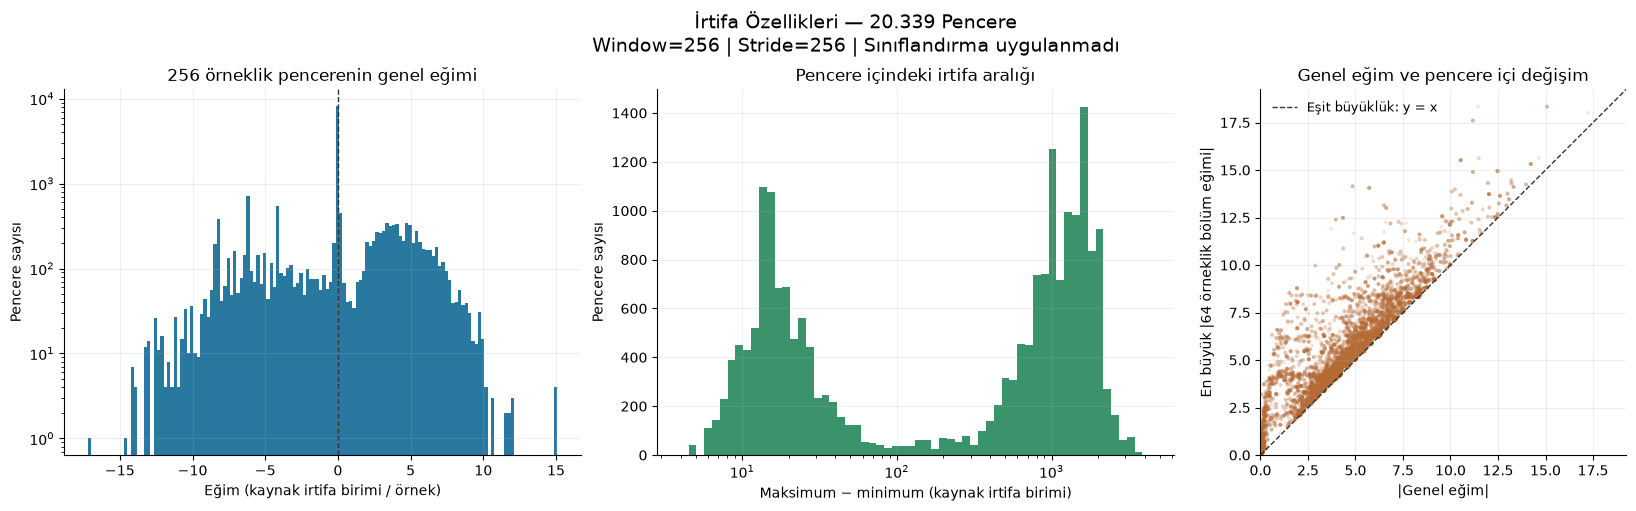

In [23]:
quarter_columns = [
    "alt_slope_q1", "alt_slope_q2",
    "alt_slope_q3", "alt_slope_q4",
]

absolute_slope = altitude_features["alt_slope"].abs()
max_absolute_quarter_slope = (
    altitude_features[quarter_columns].abs().max(axis=1)
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True,
)

# 1. Genel eğim dağılımı: bütün pencereler.
axes[0].hist(
    altitude_features["alt_slope"],
    bins="fd",
    color="#2878A0",
    edgecolor="none",
)
axes[0].axvline(0, color="#333333", linestyle="--", linewidth=1)
axes[0].set(
    title="256 örneklik pencerenin genel eğimi",
    xlabel="Eğim (kaynak irtifa birimi / örnek)",
    ylabel="Pencere sayısı",
    yscale="log",
)

# 2. İrtifa aralığı: logaritmik X ekseniyle küçük değişimleri de göster.
altitude_ranges = altitude_features["alt_range"]
assert altitude_ranges.gt(0).all(), (
    "Sıfır irtifa aralığı var; logaritmik histogram ayrıca düzenlenmeli."
)

range_bins = np.geomspace(
    altitude_ranges.min(),
    altitude_ranges.max(),
    61,
)

axes[1].hist(
    altitude_ranges,
    bins=range_bins,
    color="#3B936C",
    edgecolor="none",
)
axes[1].set(
    title="Pencere içindeki irtifa aralığı",
    xlabel="Maksimum − minimum (kaynak irtifa birimi)",
    ylabel="Pencere sayısı",
    xscale="log",
)

# 3. Genel eğim ile en büyük alt bölüm eğiminin karşılaştırılması.
axes[2].scatter(
    absolute_slope,
    max_absolute_quarter_slope,
    s=8,
    alpha=0.15,
    color="#B66B35",
    edgecolors="none",
    rasterized=True,
)

upper = max(
    absolute_slope.max(),
    max_absolute_quarter_slope.max(),
) * 1.05

axes[2].plot(
    [0, upper], [0, upper],
    "--",
    color="#333333",
    linewidth=1,
    label="Eşit büyüklük: y = x",
)
axes[2].set(
    xlim=(0, upper),
    ylim=(0, upper),
    title="Genel eğim ve pencere içi değişim",
    xlabel="|Genel eğim|",
    ylabel="En büyük |64 örneklik bölüm eğimi|",
)
axes[2].set_aspect("equal", adjustable="box")
axes[2].legend(frameon=False, fontsize=9)

for ax in axes:
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "İrtifa Özellikleri — 20.339 Pencere\n"
    "Window=256 | Stride=256 | Sınıflandırma uygulanmadı",
    fontsize=14,
)

plt.show()

## Dağılımların Yorumu ve Örnek Pencere İncelemesi

Genel eğim dağılımında sıfıra yakın belirgin bir yoğunlaşma vardır.
İrtifa aralığı dağılımında ise düşük ve yüksek değişimli pencereler
ayrı yoğunlaşmalar oluşturmaktadır.

Bu görünüm, düz ve değişken irtifa davranışlarını ayırmanın mümkün
olabileceğini düşündürür; ancak henüz sayısal bir eşik belirlenmemiştir.
Histogram kutuları veya aradaki düşük yoğunluk tek başına eşik seçimi
için yeterli değildir.

Bazı pencerelerde en büyük alt bölüm eğimi, genel eğimden belirgin
biçimde büyüktür. Bunun nedeni evre geçişi olabileceği gibi aynı yöndeki
tırmanış veya alçalmanın hızlanması/yavaşlaması da olabilir.

### Sonraki kontrol

Tahmin hataları kullanılmadan şu örnekler seçilecektir:

- İrtifa aralığı en küçük pencere.
- Genel eğimi en büyük pozitif pencere.
- Genel eğimi en büyük negatif pencere.
- En büyük mutlak alt bölüm eğimi ile mutlak genel eğimi arasındaki
  farkın en büyük olduğu pencere.

Her örnekte 256 ölçümlük irtifa profili, 64 örneklik bölüm sınırları
ve aynı uçuş içindeki çevre profili incelenecektir.

Bunlar yöntem kontrolü için seçilen uç örneklerdir; tipik pencereleri
veya bütün uçuşları temsil ettikleri varsayılmayacaktır.
Düz irtifa davranışı, uçuş bağlamı incelenmeden seyir olarak
adlandırılmayacaktır.

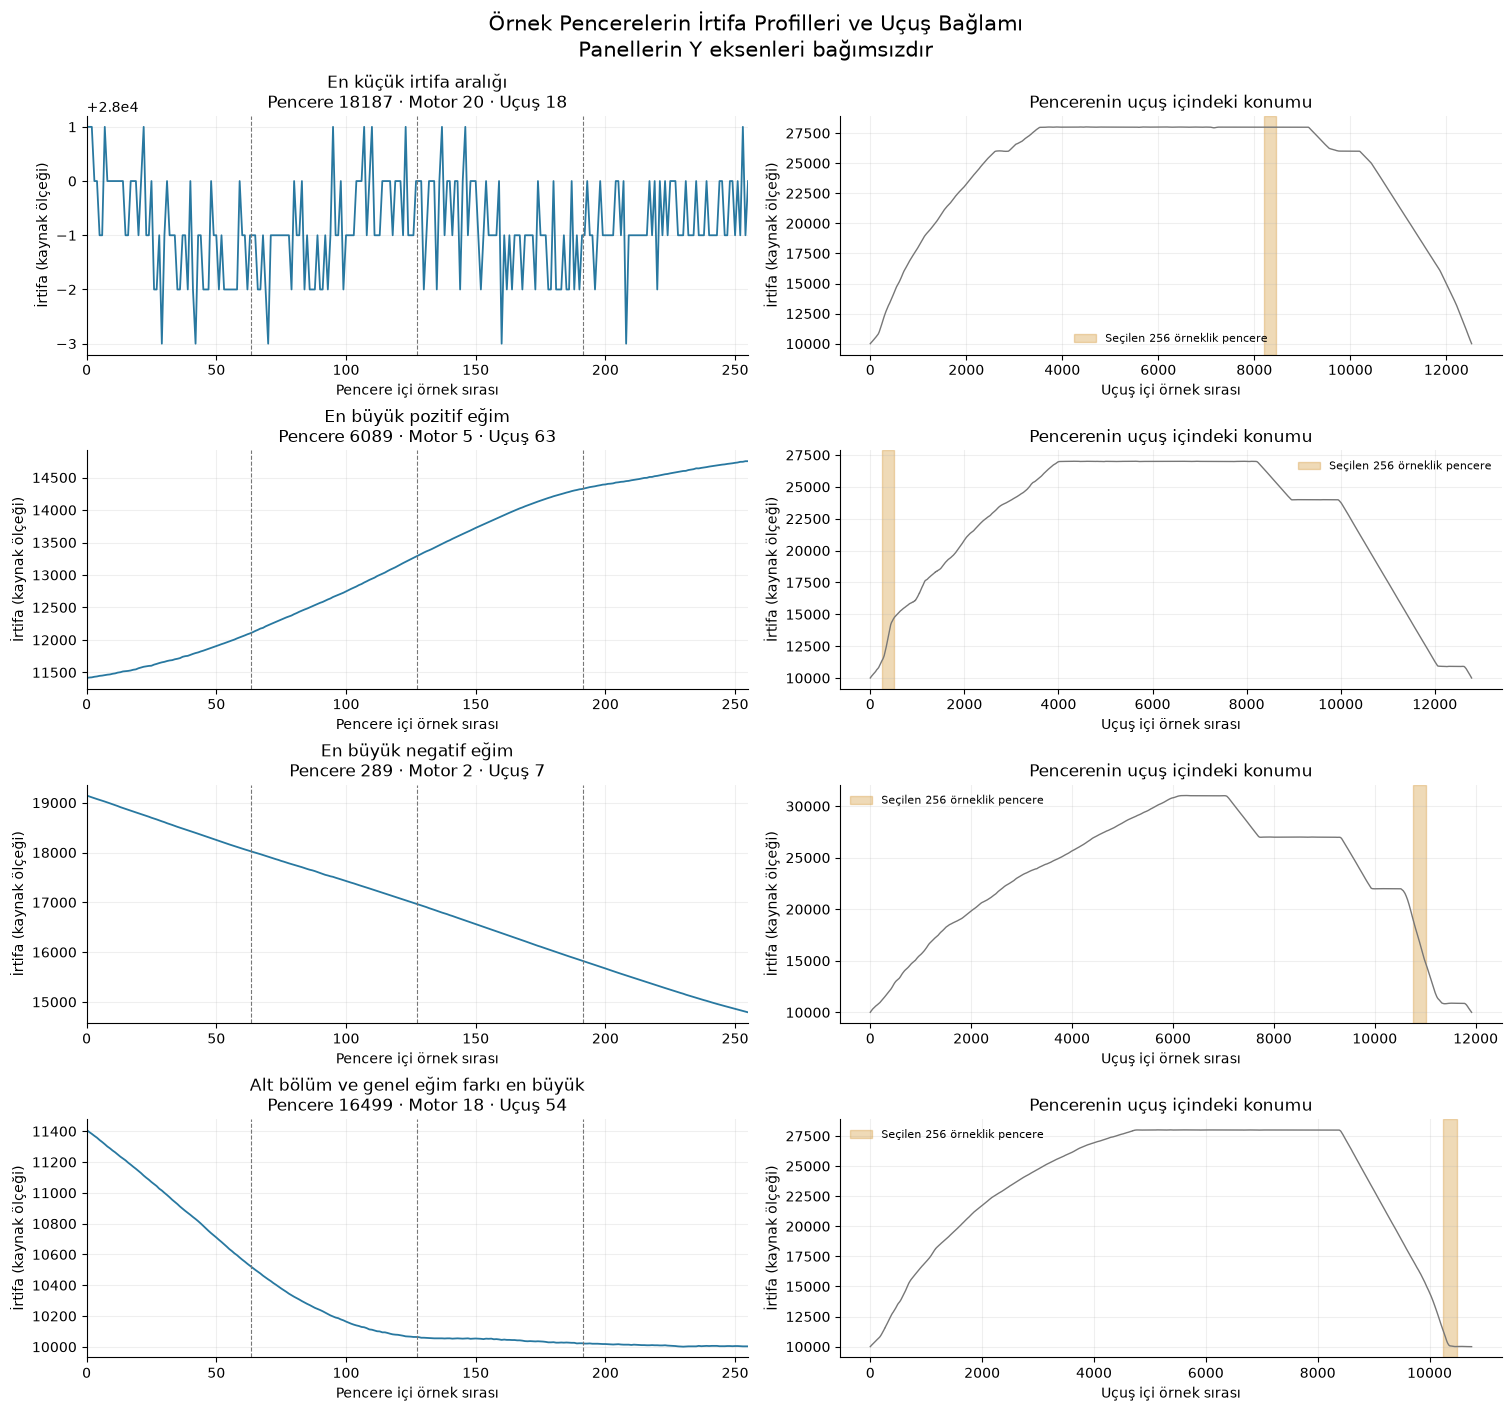

,Seçim,window_id,Motor,Uçuş,İrtifa aralığı,Genel eğim,Bölüm 1 eğimi,Bölüm 2 eğimi,Bölüm 3 eğimi,Bölüm 4 eğimi
0,En küçük irtifa aralığı,18187,20,18,4.0,0.0004,-0.0332,0.0231,-0.0215,0.0087
1,En büyük pozitif eğim,6089,5,63,3338.0,15.0811,10.8927,18.3306,16.7131,6.7594
2,En büyük negatif eğim,289,2,7,4354.0,-17.2114,-17.8427,-16.4511,-18.0040,-16.3413
3,Alt bölüm ve genel eğim farkı en büyük,16499,18,54,1408.0,-4.8509,-14.1461,-7.1255,-0.6095,-0.2964


In [24]:
quarter_columns = [
    "alt_slope_q1", "alt_slope_q2",
    "alt_slope_q3", "alt_slope_q4",
]

inspection_features = altitude_features.copy()
inspection_features["slope_gap"] = (
    inspection_features[quarter_columns].abs().max(axis=1)
    - inspection_features["alt_slope"].abs()
)

selections = [
    ("En küçük irtifa aralığı",
     inspection_features["alt_range"].idxmin()),
    ("En büyük pozitif eğim",
     inspection_features["alt_slope"].idxmax()),
    ("En büyük negatif eğim",
     inspection_features["alt_slope"].idxmin()),
    ("Alt bölüm ve genel eğim farkı en büyük",
     inspection_features["slope_gap"].idxmax()),
]

flight_lookup = flight_catalog.set_index(["unit", "cycle"])
example_rows = []

fig, axes = plt.subplots(
    4, 2,
    figsize=(15, 14),
    constrained_layout=True,
)

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")

    for row_index, (reason, index) in enumerate(selections):
        window = inspection_features.loc[index]

        unit = int(window["unit"])
        cycle = int(window["cycle"])
        window_id = int(window["window_id"])

        flight = flight_lookup.loc[(unit, cycle)]
        flight_start = int(flight["start_row"])
        flight_end = int(flight["end_row"])

        start = int(window["start_row"])
        end = int(window["end_row"])

        assert flight_start <= start < end <= flight_end
        assert end - start == 256

        flight_altitude = h5["W_dev"][
            flight_start:flight_end, altitude_index
        ]
        assert np.isfinite(flight_altitude).all()

        local_start = start - flight_start
        local_end = end - flight_start
        window_altitude = flight_altitude[local_start:local_end]

        # Sol: yalnızca seçilen pencere.
        ax_window = axes[row_index, 0]
        ax_window.plot(
            np.arange(256),
            window_altitude,
            color="#2878A0",
            linewidth=1.3,
        )

        for boundary in [63.5, 127.5, 191.5]:
            ax_window.axvline(
                boundary,
                color="#777777",
                linestyle="--",
                linewidth=0.8,
            )

        ax_window.set(
            title=f"{reason}\nPencere {window_id} · Motor {unit} · Uçuş {cycle}",
            xlabel="Pencere içi örnek sırası",
            ylabel="İrtifa (kaynak ölçeği)",
            xlim=(0, 255),
        )

        # Sağ: aynı uçuşun tamamı ve pencerenin konumu.
        ax_flight = axes[row_index, 1]
        ax_flight.plot(
            np.arange(len(flight_altitude)),
            flight_altitude,
            color="#777777",
            linewidth=1,
        )
        ax_flight.axvspan(
            local_start,
            local_end - 1,
            color="#D29532",
            alpha=0.35,
            label="Seçilen 256 örneklik pencere",
        )
        ax_flight.set(
            title="Pencerenin uçuş içindeki konumu",
            xlabel="Uçuş içi örnek sırası",
            ylabel="İrtifa (kaynak ölçeği)",
        )
        ax_flight.legend(frameon=False, fontsize=8)

        example_rows.append({
            "Seçim": reason,
            "window_id": window_id,
            "Motor": unit,
            "Uçuş": cycle,
            "İrtifa aralığı": window["alt_range"],
            "Genel eğim": window["alt_slope"],
            **{
                f"Bölüm {i + 1} eğimi": window[column]
                for i, column in enumerate(quarter_columns)
            },
        })

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Örnek Pencerelerin İrtifa Profilleri ve Uçuş Bağlamı\n"
    "Panellerin Y eksenleri bağımsızdır",
    fontsize=15,
)

plt.show()

example_summary = pd.DataFrame(example_rows)
display(example_summary.round(4))

## Örnek Pencerelerden Etiketleme Yöntemine

Ham profiller, genel eğimin tek başına yeterli olmadığını göstermektedir.

Pencere 18187, ana yüksek irtifa platosunda küçük dalgalanmalar
içermektedir. Pencere 16499 ise alçalıştan düşük irtifadaki düz bölüme
geçmektedir. İki penceredeki düz davranış aynı uçuş bağlamını taşımaz.

### İki aşamalı yaklaşım

1. **Yerel irtifa davranışı:** Yükselen, yaklaşık düz, alçalan veya
   geçiş/belirsiz davranışın belirlenmesi.
2. **Uçuş bağlamı:** Düz bölgenin ana seyir platosuna mı, yoksa
   tırmanış/alçalma içindeki bir ara düz bölgeye mi ait olduğunun incelenmesi.

Yerel davranış ile uçuş evresi aynı şey değildir. Ana plato dışında
kalan düz bölümler doğrudan seyir olarak adlandırılmayacaktır.

### Eşik belirlemeden önce

Dağılım grafiklerinde sıfır çevresinde yoğunlaşma görülmektedir.
Sonraki adımda genel eğimin ve 64 örneklik bölüm eğimlerinin sıfıra yakın
bölgeleri daha ayrıntılı incelenecektir.

Amaç, küçük dalgalanmalar ile sürekli irtifa değişiminin ayrışıp
ayrışmadığını değerlendirmektir. Belirgin bir ayrım yoksa tek bir
keskin eşik yerine belirsizlik bölgesi kullanılacaktır.

Seçilecek aday eşikler farklı motor ve uçuşlarda kontrol edilecek;
etiketlerin eşik ve inceleme ölçeği değişimine duyarlılığı değerlendirilecektir.
Tahmin hataları eşik seçiminde kullanılmayacaktır.

Dört alt bölüm, geçişleri incelemek için başlangıç yaklaşımıdır.
64 örnekten kısa değişimleri kaçırabileceği için tek başına
pencerenin saf bir evre içerdiğinin kanıtı sayılmayacaktır.

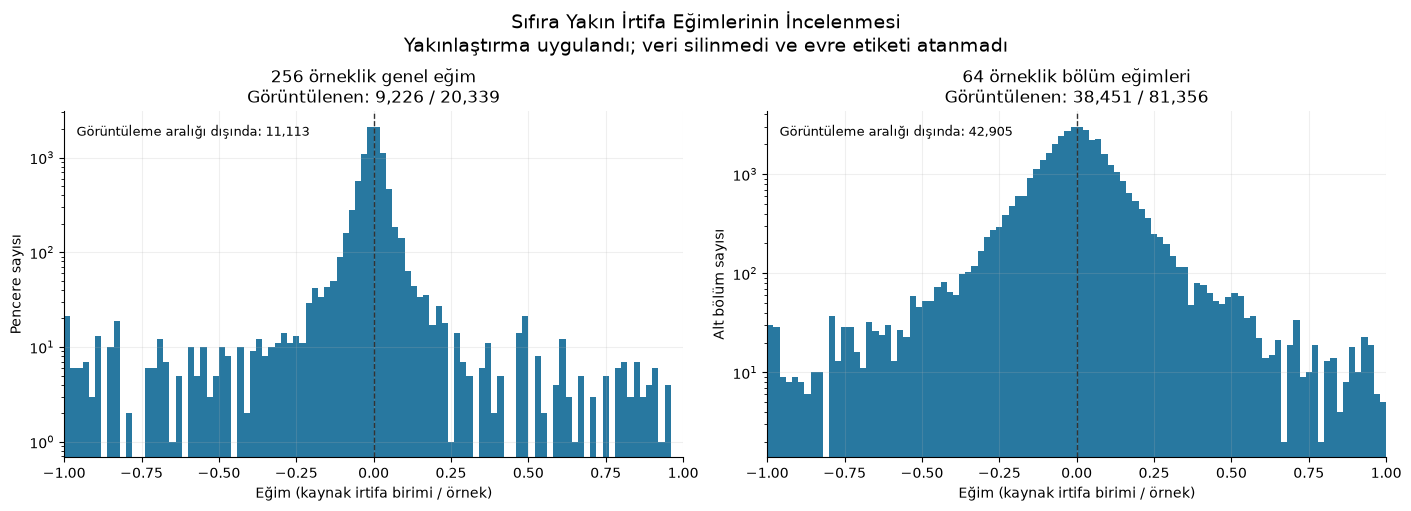

,Toplam pencere,Grafik aralığındaki pencere,Grafik aralığındaki oran (%)
unit,,,
2,3294,1441,43.75
5,3990,1837,46.04
10,3685,1638,44.45
16,2955,1385,46.87
18,3446,1539,44.66
20,2969,1386,46.68


In [25]:
quarter_columns = [
    "alt_slope_q1", "alt_slope_q2",
    "alt_slope_q3", "alt_slope_q4",
]

general_slopes = altitude_features["alt_slope"].to_numpy()
quarter_slopes = (
    altitude_features[quarter_columns]
    .to_numpy()
    .ravel()
)

zoom_limit = 1.0  # Yalnızca görsel yakınlaştırma.
zoom_bins = np.linspace(-zoom_limit, zoom_limit, 101)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    constrained_layout=True,
)

for ax, values, title, observation_name in [
    (
        axes[0],
        general_slopes,
        "256 örneklik genel eğim",
        "Pencere",
    ),
    (
        axes[1],
        quarter_slopes,
        "64 örneklik bölüm eğimleri",
        "Alt bölüm",
    ),
]:
    inside = np.abs(values) <= zoom_limit
    outside_count = int((~inside).sum())

    ax.hist(
        values[inside],
        bins=zoom_bins,
        color="#2878A0",
        edgecolor="none",
    )
    ax.axvline(0, color="#333333", linestyle="--", linewidth=1)

    ax.set(
        title=(
            f"{title}\n"
            f"Görüntülenen: {inside.sum():,} / {len(values):,}"
        ),
        xlabel="Eğim (kaynak irtifa birimi / örnek)",
        ylabel=f"{observation_name} sayısı",
        xlim=(-zoom_limit, zoom_limit),
        yscale="log",
    )
    ax.text(
        0.02, 0.96,
        f"Görüntüleme aralığı dışında: {outside_count:,}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
    )
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Sıfıra Yakın İrtifa Eğimlerinin İncelenmesi\n"
    "Yakınlaştırma uygulandı; veri silinmedi ve evre etiketi atanmadı",
    fontsize=14,
)

plt.show()

# Aynı aralıkta kalan genel eğimleri motor bazında da göster.
zoom_counts = (
    altitude_features
    .assign(in_zoom=altitude_features["alt_slope"].abs().le(zoom_limit))
    .groupby("unit")
    .agg(
        total_windows=("window_id", "size"),
        windows_in_zoom=("in_zoom", "sum"),
    )
)

zoom_counts["percentage_in_zoom"] = (
    100 * zoom_counts["windows_in_zoom"]
    / zoom_counts["total_windows"]
)

display(
    zoom_counts.rename(columns={
        "total_windows": "Toplam pencere",
        "windows_in_zoom": "Grafik aralığındaki pencere",
        "percentage_in_zoom": "Grafik aralığındaki oran (%)",
    }).style.format({
        "Grafik aralığındaki oran (%)": "{:.2f}",
    })
)

## Eğim Toleransları İçin Adayların Değerlendirilmesi

Genel eğim ve alt bölüm eğimleri sıfır çevresinde yoğunlaşmaktadır.
Ancak dağılımlarda düz davranış ile yavaş irtifa değişimini kesin
olarak ayıran bir sınır görülmemektedir.

64 örneklik bölüm eğimlerinin daha geniş dağılımı, toleransın inceleme
ölçeğine bağlı olduğunu göstermektedir.

### Aday toleransları nasıl inceleyeceğiz?

64 örneklik bölüm eğimleri için 0.1, 0.2, 0.3 ve 0.5 kaynak irtifa
birimi/örnek değerleri, gözlenen merkez yoğunluğu ve kuyruklarını
karşılaştırmak amacıyla aday olarak değerlendirilecektir.

Bunlar doğrulanmış eşikler veya fiziksel dikey hız sınırları değildir.

Her aday tolerans için pencereler geçici olarak:

- Dört bölümün tamamı toleransın üzerinde pozitif eğimli,
- Dört bölümün tamamı toleransın altında negatif eğimli,
- Dört bölümün tamamı mutlak değerce tolerans içinde,
- Bu koşulların hiçbirini karşılamayan

şeklinde sayılacaktır.

Bu gruplar henüz tırmanış, seyir ve alçalma etiketleri değildir.
Özellikle tolerans içindeki pencereler arasında ara platolar ve
yavaş irtifa değişimleri bulunabilir.

Amaç, aday tolerans değiştiğinde kaç pencerenin grubunun değiştiğini
görmektir. Değişen pencereler ham uçuş profilleri üzerinde kontrol
edilecek; seçim tahmin hatalarına göre yapılmayacaktır.

In [26]:
quarter_columns = [
    "alt_slope_q1", "alt_slope_q2",
    "alt_slope_q3", "alt_slope_q4",
]

candidate_tolerances = [0.1, 0.2, 0.3, 0.5]
quarter_values = altitude_features[quarter_columns].to_numpy()

assert np.isfinite(quarter_values).all()
assert altitude_features["window_id"].is_unique

# Her adayın gruplarını sakla; değişen pencereleri sonra inceleyeceğiz.
candidate_groups = pd.DataFrame(
    index=pd.Index(
        altitude_features["window_id"].to_numpy(),
        name="window_id",
    )
)

sensitivity_rows = []
previous_groups = None

for tolerance in candidate_tolerances:
    all_positive = (quarter_values > tolerance).all(axis=1)
    all_negative = (quarter_values < -tolerance).all(axis=1)
    all_within = (np.abs(quarter_values) <= tolerance).all(axis=1)

    # Üç koşul aynı pencere için birlikte gerçekleşmemeli.
    membership_count = (
        all_positive.astype(int)
        + all_negative.astype(int)
        + all_within.astype(int)
    )
    assert (membership_count <= 1).all()

    groups = np.select(
        [all_positive, all_negative, all_within],
        ["Tümü pozitif", "Tümü negatif", "Tümü tolerans içinde"],
        default="Diğer / geçiş adayı",
    )

    candidate_groups[tolerance] = groups

    positive_count = int(all_positive.sum())
    negative_count = int(all_negative.sum())
    within_count = int(all_within.sum())
    other_count = int((membership_count == 0).sum())

    assert (
        positive_count + negative_count + within_count + other_count
        == len(altitude_features)
    )

    changed_count = (
        pd.NA if previous_groups is None
        else int((groups != previous_groups).sum())
    )

    sensitivity_rows.append({
        "Tolerans": tolerance,
        "Tümü pozitif": positive_count,
        "Tümü negatif": negative_count,
        "Tümü tolerans içinde": within_count,
        "Diğer / geçiş adayı": other_count,
        "Önceki toleransa göre değişen": changed_count,
    })

    previous_groups = groups.copy()

tolerance_summary = pd.DataFrame(sensitivity_rows)
tolerance_summary["Önceki toleransa göre değişen"] = (
    tolerance_summary["Önceki toleransa göre değişen"].astype("Int64")
)

display(
    tolerance_summary.style
    .hide(axis="index")
    .format({"Tolerans": "{:.1f}"}, na_rep="—")
)

print("Her toleransta değerlendirilen pencere:", len(altitude_features))
print("İlk satırda önceki tolerans olmadığı için değişim sayısı gösterilmez.")

Tolerans,Tümü pozitif,Tümü negatif,Tümü tolerans içinde,Diğer / geçiş adayı,Önceki toleransa göre değişen
0.1,6113,4070,2262,7894,—
0.2,6055,3962,5754,4568,3658
0.3,5992,3914,7328,3105,1685
0.5,5947,3864,8136,2392,903


Her toleransta değerlendirilen pencere: 20339
İlk satırda önceki tolerans olmadığı için değişim sayısı gösterilmez.


## Tolerans Duyarlılığının İncelenmesi

Tolerans 0.1’den 0.5’e yükseldiğinde dört bölümün tamamı tolerans
içinde kalan pencere sayısı 2.262’den 8.136’ya yükselmektedir.
“Diğer / geçiş adayı” grubunun büyüklüğü ise azalmaktadır.

Bu sonuç, düz davranış adaylarının seçiminin toleransa duyarlı
olduğunu gösterir. Daha az belirsiz pencere üretmek, tek başına
daha doğru sınıflandırma anlamına gelmez.

### Sonraki kontrol: Değişimin yönü

Her ardışık tolerans çifti için geçiş tablosu oluşturulacaktır:

- 0.1 → 0.2
- 0.2 → 0.3
- 0.3 → 0.5

Tablolar, pencerelerin hangi gruptan hangi gruba geçtiğini gösterecektir.
Özellikle iki değişim ayrı incelenecektir:

1. “Diğer / geçiş adayı” grubundan “Tümü tolerans içinde” grubuna geçiş.
2. Tutarlı pozitif veya negatif gruptan başka bir gruba geçiş.

İlk değişim küçük dalgalanmaların tolere edilmesiyle, ikinci değişim
ise yavaş yükseliş/alçalışın artık belirgin kabul edilmemesiyle ilişkili
olabilir. Bunlar ham profiller kontrol edilmeden kesinleştirilmeyecektir.

Eşik seçilmeden önce değişen pencereler farklı motorlardan örneklenerek
incelenecektir. Seçimde RUL veya tahmin hatası kullanılmayacaktır.

In [27]:
group_order = [
    "Tümü pozitif",
    "Tümü negatif",
    "Tümü tolerans içinde",
    "Diğer / geçiş adayı",
]

transition_tables = {}

for previous_tolerance, next_tolerance in zip(
    candidate_tolerances[:-1],
    candidate_tolerances[1:],
):
    previous = candidate_groups[previous_tolerance]
    following = candidate_groups[next_tolerance]

    assert previous.notna().all() and following.notna().all()
    assert previous.isin(group_order).all()
    assert following.isin(group_order).all()

    transition = pd.crosstab(
        previous,
        following,
        rownames=["Önceki grup"],
        colnames=["Sonraki grup"],
    ).reindex(
        index=group_order,
        columns=group_order,
        fill_value=0,
    )

    total = int(transition.to_numpy().sum())
    unchanged = int(np.trace(transition.to_numpy()))
    changed = int(previous.ne(following).sum())

    assert total == len(candidate_groups)
    assert total - unchanged == changed

    transition_tables[
        (previous_tolerance, next_tolerance)
    ] = transition

    print(
        f"\nTolerans {previous_tolerance:.1f} → {next_tolerance:.1f}"
        f"\nDeğişmeyen: {unchanged:,} | Değişen: {changed:,}"
    )

    display(transition.style.format("{:d}"))


Tolerans 0.1 → 0.2
Değişmeyen: 16,681 | Değişen: 3,658


Sonraki grup,Tümü pozitif,Tümü negatif,Tümü tolerans içinde,Diğer / geçiş adayı
Önceki grup,,,,
Tümü pozitif,6055,0,0,58
Tümü negatif,0,3962,0,108
Tümü tolerans içinde,0,0,2262,0
Diğer / geçiş adayı,0,0,3492,4402



Tolerans 0.2 → 0.3
Değişmeyen: 18,654 | Değişen: 1,685


Sonraki grup,Tümü pozitif,Tümü negatif,Tümü tolerans içinde,Diğer / geçiş adayı
Önceki grup,,,,
Tümü pozitif,5992,0,0,63
Tümü negatif,0,3914,0,48
Tümü tolerans içinde,0,0,5754,0
Diğer / geçiş adayı,0,0,1574,2994



Tolerans 0.3 → 0.5
Değişmeyen: 19,436 | Değişen: 903


Sonraki grup,Tümü pozitif,Tümü negatif,Tümü tolerans içinde,Diğer / geçiş adayı
Önceki grup,,,,
Tümü pozitif,5947,0,0,45
Tümü negatif,0,3864,0,50
Tümü tolerans içinde,0,0,7328,0
Diğer / geçiş adayı,0,0,808,2297


## Toleransla Grubu Değişen Pencerelerin Kontrolü

Tolerans artışında en büyük geçiş, “Diğer / geçiş adayı” grubundan
“Tümü tolerans içinde” grubuna olmuştur:

| Tolerans değişimi | Tolerans içine geçen | Pozitif/negatif gruptan diğer gruba geçen |
|---|---:|---:|
| 0.1 → 0.2 | 3.492 | 166 |
| 0.2 → 0.3 | 1.574 | 111 |
| 0.3 → 0.5 | 808 | 95 |

Bu geçişler henüz doğru veya yanlış sınıflandırma olarak yorumlanamaz.
Tolerans içine alınan pencereler küçük dalgalanmalar kadar yavaş
irtifa değişimleri veya kısa geçişler de içerebilir.

### Ham profil incelemesi

Önce 0.2 → 0.3 geçişinde “Diğer / geçiş adayı” grubundan
“Tümü tolerans içinde” grubuna geçen pencereler incelenecektir.
Bu seçim 0.3 toleransının kabul edildiği anlamına gelmez.

Her motordan bir aday pencere, sabit rastgelelik tohumu ile seçilecektir.
Aday bulunmayan motor açıkça belirtilecektir. Seçimde RUL değerleri
ve model tahmin hataları kullanılmayacaktır.

Her seçilen pencere için:

- 256 örneklik ham irtifa profili,
- Dört alt bölümün eğimleri,
- Pencerenin bütün uçuş içindeki konumu

birlikte gösterilecektir.

Altı örnek yalnızca görsel kontrol içindir; bütün adayların aynı
davranışı gösterdiğini kanıtlamaz.

,Motor,Aday pencere sayısı
0,2,264
1,5,317
2,10,256
3,16,239
4,18,275
5,20,223


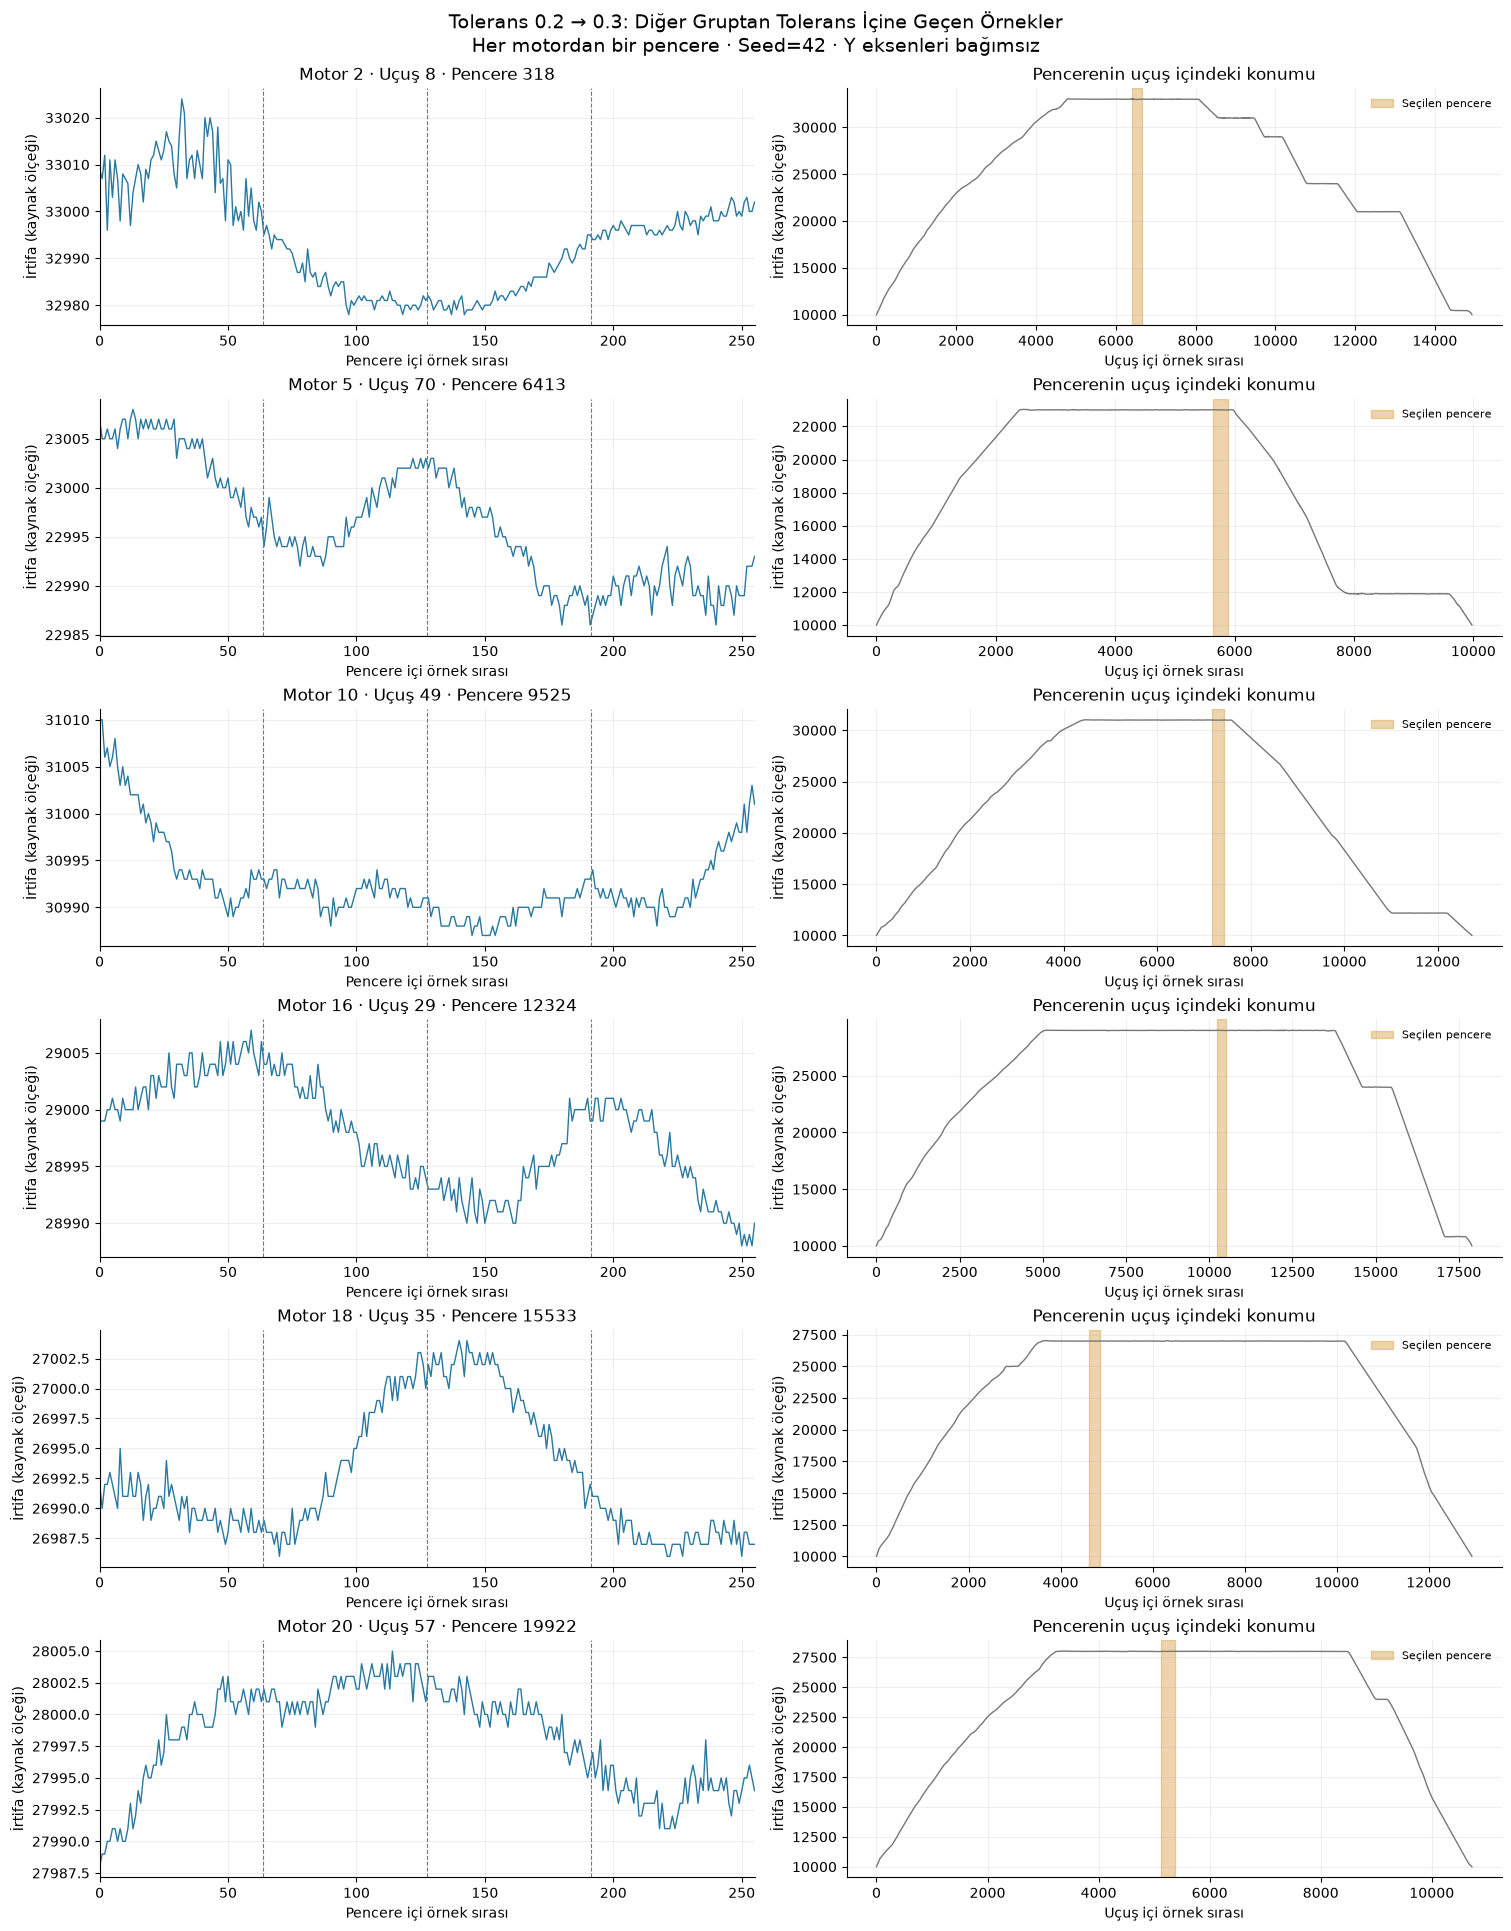

,window_id,unit,cycle,alt_range,alt_slope,alt_slope_q1,alt_slope_q2,alt_slope_q3,alt_slope_q4
0,318,2,8,46.0,-0.0462,-0.0673,-0.2494,0.2291,0.0990
1,6413,5,70,22.0,-0.0674,-0.1594,0.1530,-0.2599,0.0079
2,9525,10,49,23.0,-0.0210,-0.2795,-0.0220,0.0601,0.1427
3,12324,16,29,19.0,-0.0426,0.0989,-0.1884,0.1217,-0.2221
4,15533,18,35,18.0,-0.0032,-0.0636,0.2731,-0.1867,-0.0336
5,19922,20,57,17.0,-0.0143,0.2174,0.0510,-0.0878,-0.0056


In [28]:
transition_mask = (
    candidate_groups[0.2].eq("Diğer / geçiş adayı")
    & candidate_groups[0.3].eq("Tümü tolerans içinde")
)
candidate_ids = candidate_groups.index[transition_mask]

transition_candidates = altitude_features.loc[
    altitude_features["window_id"].isin(candidate_ids)
].copy()

assert len(transition_candidates) == int(transition_mask.sum())
assert transition_candidates["window_id"].is_unique

rng = np.random.default_rng(42)
selected_indices = []
availability = []

for unit in sorted(altitude_features["unit"].unique()):
    motor_candidates = (
        transition_candidates.loc[
            transition_candidates["unit"].eq(unit)
        ]
        .sort_values("window_id")
    )

    availability.append({
        "Motor": int(unit),
        "Aday pencere sayısı": len(motor_candidates),
    })

    if not motor_candidates.empty:
        position = int(rng.integers(len(motor_candidates)))
        selected_indices.append(motor_candidates.index[position])

selected_transition_windows = (
    transition_candidates.loc[selected_indices]
    .sort_values("unit")
    .reset_index(drop=True)
)

display(pd.DataFrame(availability))

if selected_transition_windows.empty:
    raise ValueError("Bu geçiş için örneklenebilecek pencere bulunamadı.")

flight_lookup = flight_catalog.set_index(["unit", "cycle"])

fig, axes = plt.subplots(
    len(selected_transition_windows),
    2,
    figsize=(15, 3.2 * len(selected_transition_windows)),
    squeeze=False,
    constrained_layout=True,
)

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")

    for row_number, window in enumerate(
        selected_transition_windows.itertuples(index=False)
    ):
        unit, cycle = int(window.unit), int(window.cycle)
        flight = flight_lookup.loc[(unit, cycle)]
        flight_start = int(flight["start_row"])
        flight_end = int(flight["end_row"])

        start, end = int(window.start_row), int(window.end_row)
        assert flight_start <= start < end <= flight_end
        assert end - start == 256

        flight_altitude = h5["W_dev"][
            flight_start:flight_end, altitude_index
        ]
        assert np.isfinite(flight_altitude).all()

        local_start = start - flight_start
        local_end = end - flight_start
        window_altitude = flight_altitude[local_start:local_end]

        left, right = axes[row_number]

        left.plot(
            np.arange(256), window_altitude,
            color="#2878A0", linewidth=1,
        )
        for boundary in [63.5, 127.5, 191.5]:
            left.axvline(
                boundary, color="#777777",
                linestyle="--", linewidth=0.8,
            )

        left.set(
            title=(
                f"Motor {unit} · Uçuş {cycle} · "
                f"Pencere {int(window.window_id)}"
            ),
            xlabel="Pencere içi örnek sırası",
            ylabel="İrtifa (kaynak ölçeği)",
            xlim=(0, 255),
        )
        left.ticklabel_format(axis="y", style="plain", useOffset=False)

        right.plot(
            np.arange(len(flight_altitude)),
            flight_altitude,
            color="#777777", linewidth=1,
        )
        right.axvspan(
            local_start, local_end - 1,
            color="#D29532", alpha=0.4,
            label="Seçilen pencere",
        )
        right.set(
            title="Pencerenin uçuş içindeki konumu",
            xlabel="Uçuş içi örnek sırası",
            ylabel="İrtifa (kaynak ölçeği)",
        )
        right.legend(frameon=False, fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Tolerans 0.2 → 0.3: Diğer Gruptan Tolerans İçine Geçen Örnekler\n"
    "Her motordan bir pencere · Seed=42 · Y eksenleri bağımsız",
    fontsize=14,
)

plt.show()

display(
    selected_transition_windows[
        [
            "window_id", "unit", "cycle",
            "alt_range", "alt_slope",
            "alt_slope_q1", "alt_slope_q2",
            "alt_slope_q3", "alt_slope_q4",
        ]
    ].round(4)
)

## 0.2 → 0.3 Geçişindeki Örneklerin Değerlendirilmesi

İncelenen altı pencere, uçuş profillerinin ana plato bölgelerinde
veya plato sonuna yakın konumdadır.

İrtifa aralıkları 17–46 kaynak birimi arasındadır. Genel eğimler
sıfıra yakındır; alt bölüm eğimleri ise küçük pozitif ve negatif
değerler alabilmektedir.

Bu örneklerde 0.2 toleransının aşılması, tek başına uçuş evresi
değişimi göstergesi değildir. 0.3 toleransı, incelenen plato
dalgalanmalarını kapsayan bir adaydır; henüz nihai eşik değildir.

### Karşı kontrol: Yavaş irtifa değişimleri

Sonraki adımda 0.2 toleransında dört bölümün tamamı pozitif veya
negatifken, 0.3 toleransında “Diğer / geçiş adayı” grubuna geçen
111 pencere incelenecektir.

Bu pencerelerde en az bir bölümün eğim büyüklüğü 0.2–0.3
aralığındadır. Amaç, bunların sürekli yavaş yükseliş/alçalış mı,
yoksa düz bölgeye giriş veya çıkış mı içerdiğini anlamaktır.

Motor ve önceki davranış grubuna göre aday sayıları çıkarılacak;
mevcut her motor–grup çiftinden sabit tohumla bir örnek seçilerek
ham pencere ve uçuş bağlamı gösterilecektir.

Seçimde RUL veya tahmin hatası kullanılmayacaktır.

Toplam karşı kontrol adayı: 111


previous_group,Tümü pozitif,Tümü negatif
unit,,
2,8,11
5,16,10
10,13,9
16,9,2
18,8,5
20,9,11


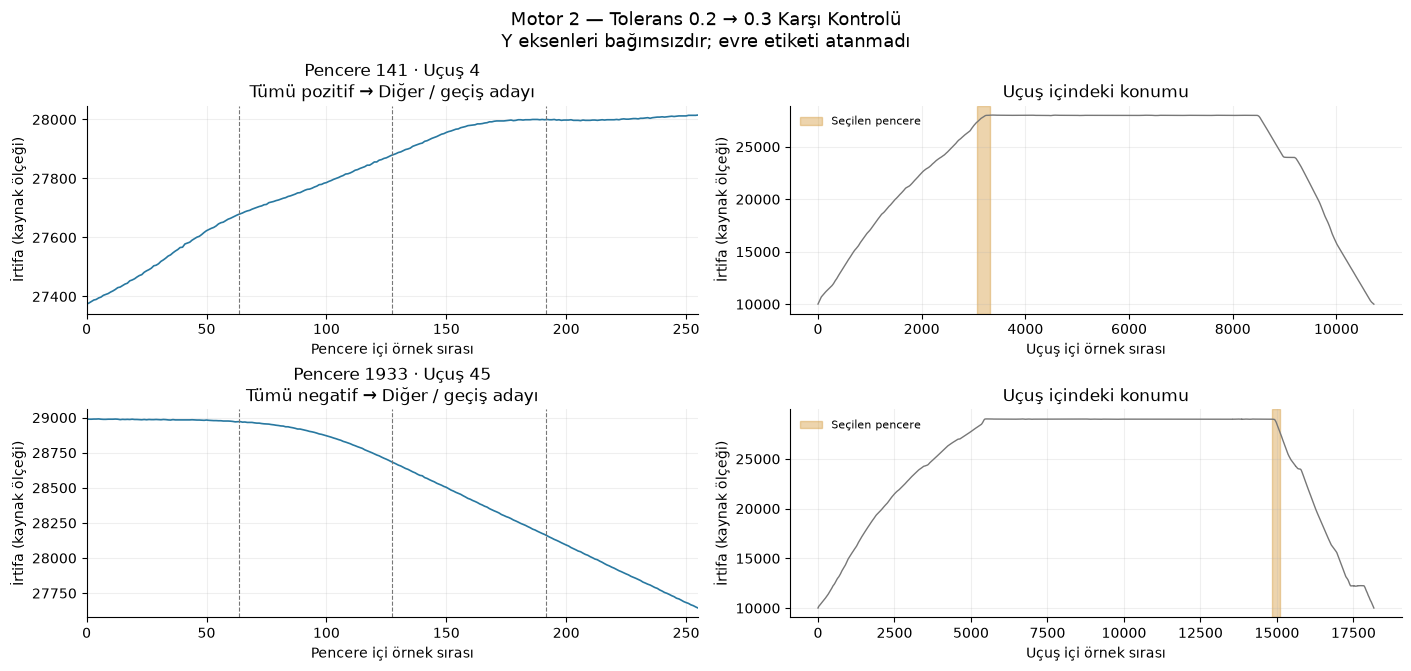

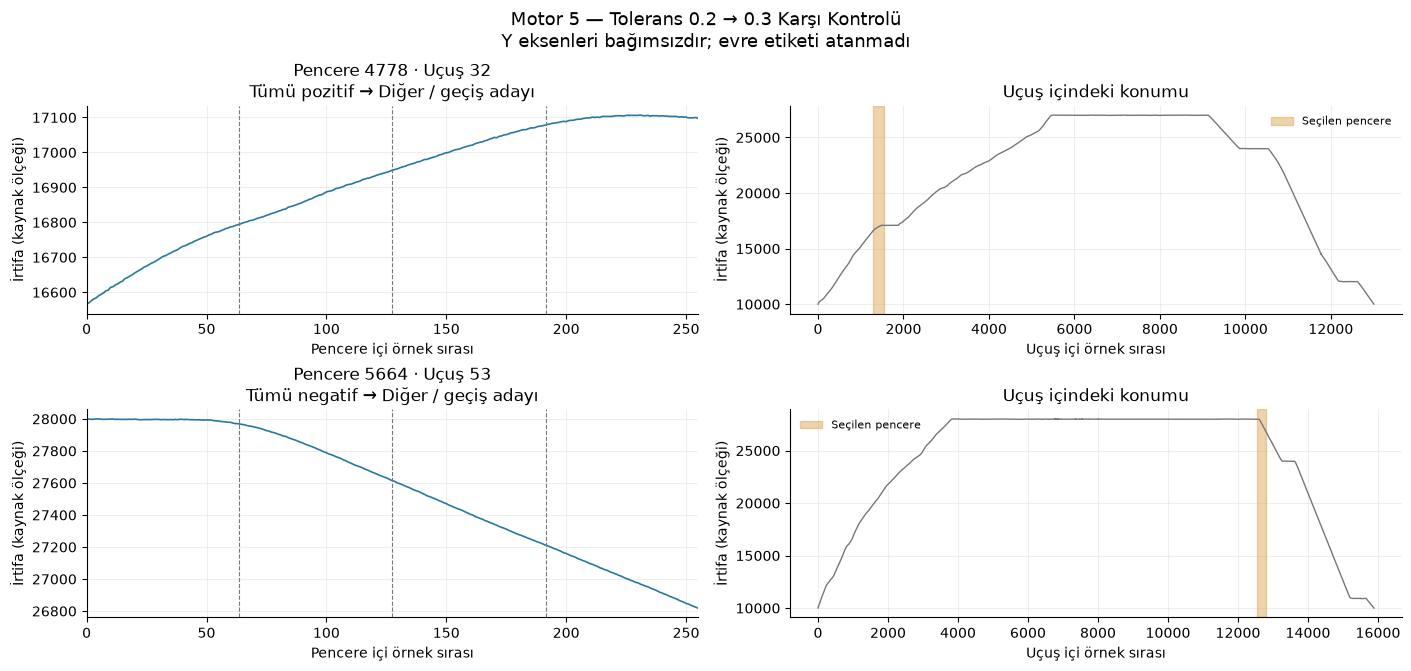

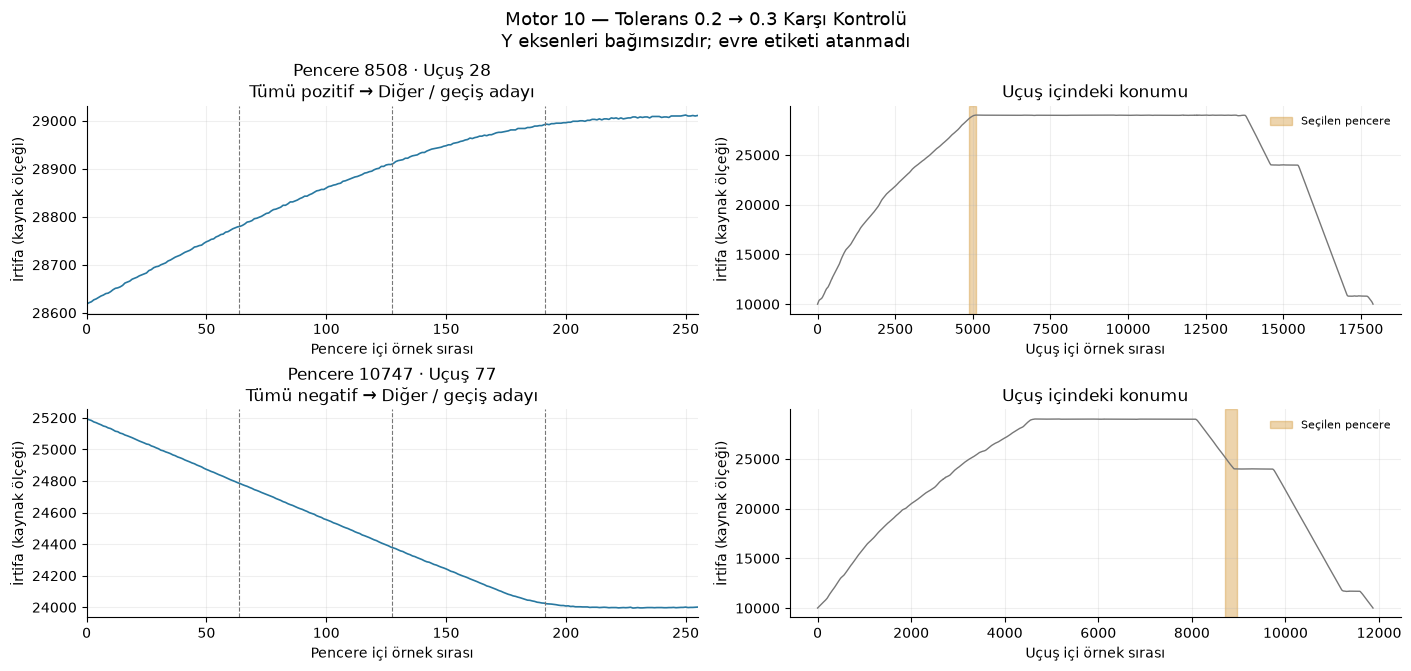

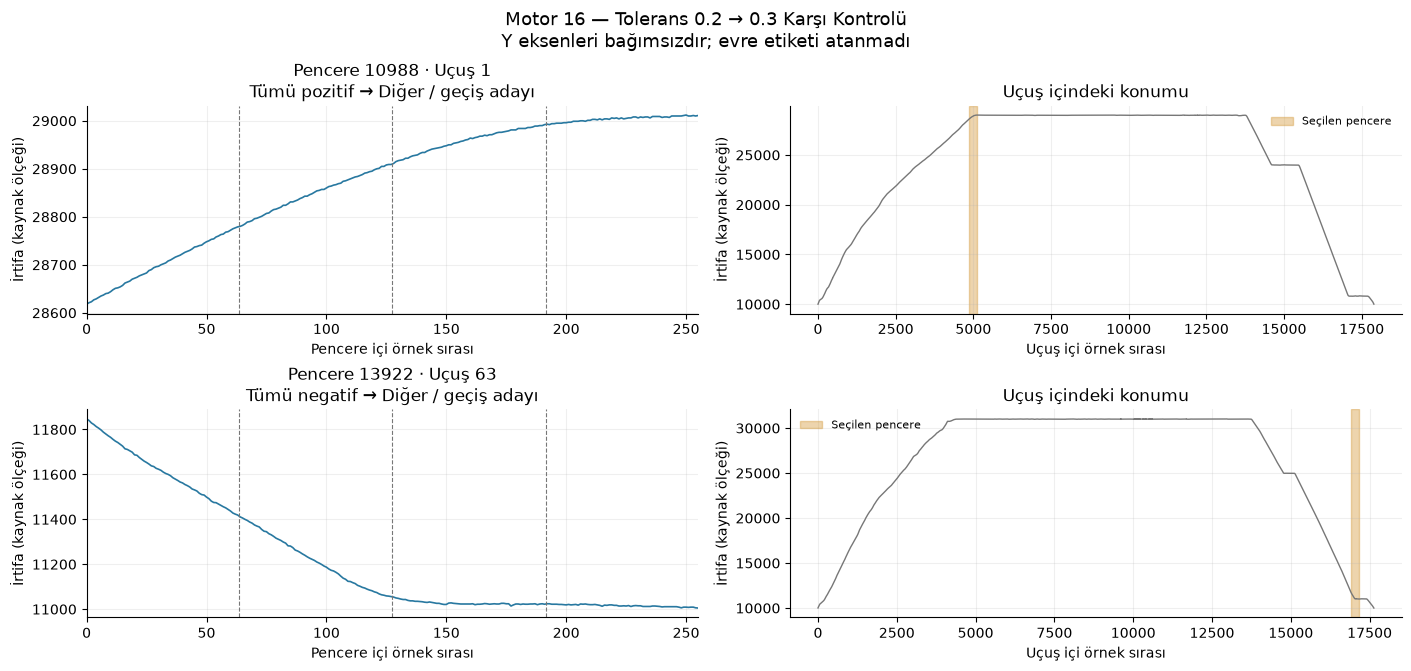

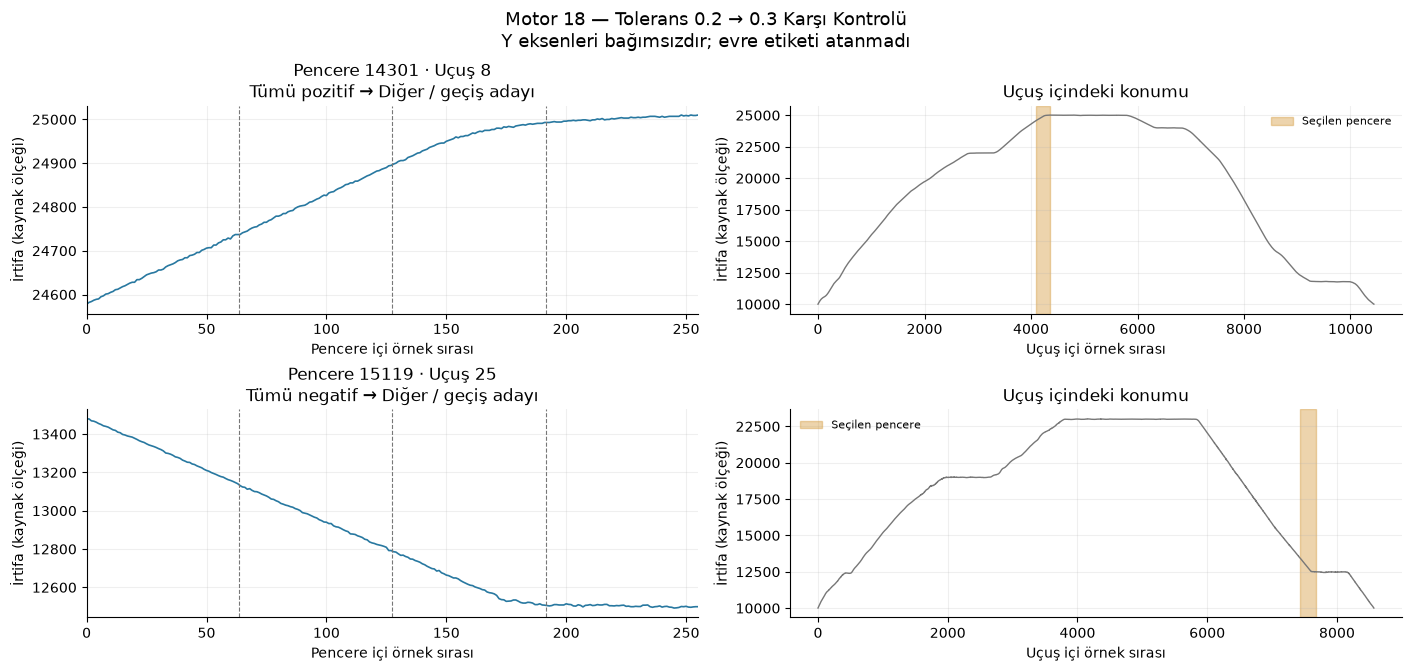

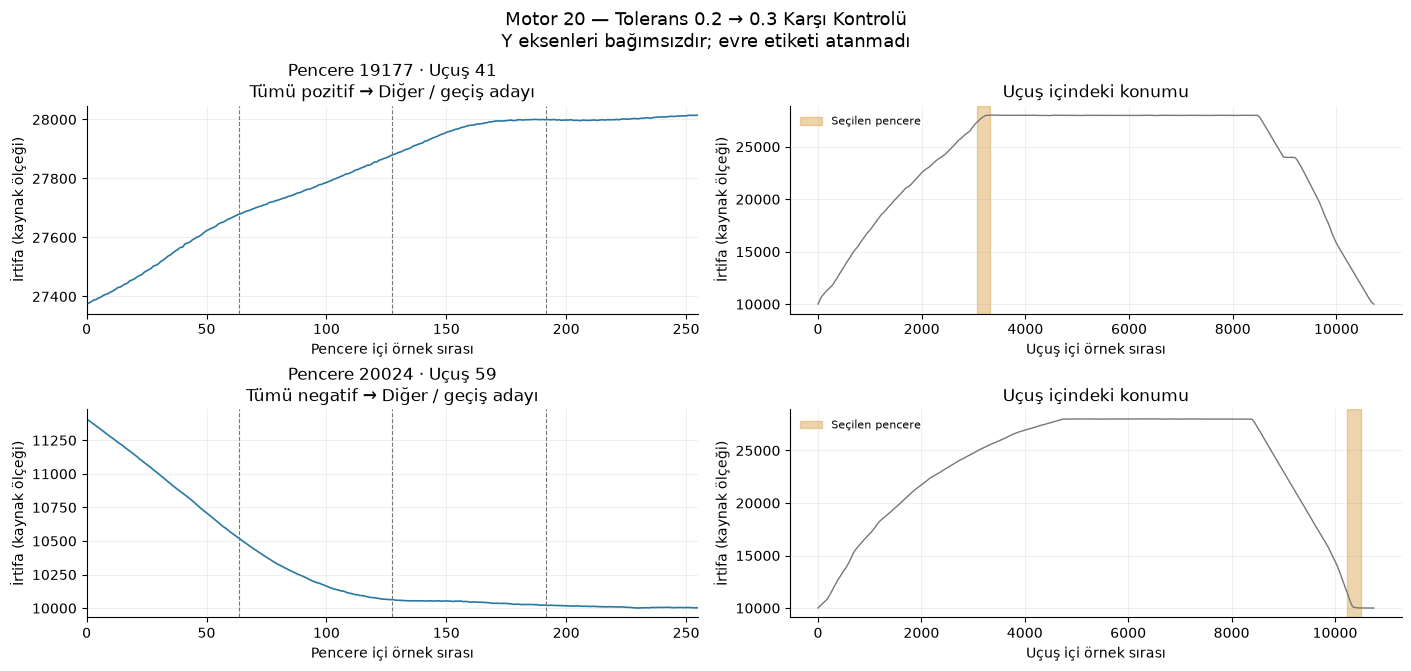

,window_id,unit,cycle,previous_group,alt_range,alt_slope,alt_slope_q1,alt_slope_q2,alt_slope_q3,alt_slope_q4
0,141,2,4,Tümü pozitif,641.0,2.5418,5.0363,3.1110,1.9250,0.2863
1,1933,2,45,Tümü negatif,1347.0,-5.7470,-0.2358,-4.4705,-8.1568,-8.1756
2,4778,5,32,Tümü pozitif,541.0,2.1323,3.6379,2.4929,2.0767,0.2615
3,5664,5,53,Tümü negatif,1181.0,-5.1802,-0.2764,-5.7677,-6.3554,-6.1821
4,8508,10,28,Tümü pozitif,394.0,1.5904,2.5599,2.0481,1.2472,0.2796
5,10747,10,77,Tümü negatif,1198.0,-5.2340,-6.4099,-6.3814,-5.8299,-0.2450
6,10988,16,1,Tümü pozitif,394.0,1.5904,2.5599,2.0481,1.2472,0.2796
7,13922,16,63,Tümü negatif,842.0,-3.1412,-6.6618,-5.9532,-0.3331,-0.2549
8,14301,18,8,Tümü pozitif,432.0,1.8206,2.5117,2.4946,1.4856,0.2580
9,15119,18,25,Tümü negatif,987.0,-4.2993,-5.4259,-5.4083,-4.7785,-0.2006


In [29]:
previous_groups = ["Tümü pozitif", "Tümü negatif"]

counter_mask = (
    candidate_groups[0.2].isin(previous_groups)
    & candidate_groups[0.3].eq("Diğer / geçiş adayı")
)

counter_candidates = altitude_features.merge(
    candidate_groups.loc[counter_mask, [0.2]]
    .rename(columns={0.2: "previous_group"})
    .reset_index(),
    on="window_id",
    how="inner",
    validate="one_to_one",
)

assert len(counter_candidates) == int(counter_mask.sum())

# Aday bulunmayan motor–grup çiftlerini de tabloda göster.
candidate_counts = (
    pd.crosstab(
        counter_candidates["unit"],
        counter_candidates["previous_group"],
    )
    .reindex(
        index=sorted(altitude_features["unit"].unique()),
        columns=previous_groups,
        fill_value=0,
    )
)

print("Toplam karşı kontrol adayı:", len(counter_candidates))
display(candidate_counts)

rng = np.random.default_rng(42)
chosen_indices = []

for unit in sorted(altitude_features["unit"].unique()):
    for previous_group in previous_groups:
        candidates = (
            counter_candidates.loc[
                counter_candidates["unit"].eq(unit)
                & counter_candidates["previous_group"].eq(previous_group)
            ]
            .sort_values("window_id")
        )

        if not candidates.empty:
            position = int(rng.integers(len(candidates)))
            chosen_indices.append(candidates.index[position])

counter_examples = (
    counter_candidates.loc[chosen_indices]
    .reset_index(drop=True)
)

if counter_examples.empty:
    raise ValueError("İncelenecek karşı kontrol örneği bulunamadı.")

flight_lookup = flight_catalog.set_index(["unit", "cycle"])

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")

    # Okunabilirlik için her motoru ayrı bir figürde göster.
    for unit, examples in counter_examples.groupby("unit", sort=True):
        fig, axes = plt.subplots(
            len(examples), 2,
            figsize=(14, 3.3 * len(examples)),
            squeeze=False,
            constrained_layout=True,
        )

        for row_number, window in enumerate(
            examples.itertuples(index=False)
        ):
            cycle = int(window.cycle)
            flight = flight_lookup.loc[(int(unit), cycle)]

            flight_start = int(flight["start_row"])
            flight_end = int(flight["end_row"])
            start, end = int(window.start_row), int(window.end_row)

            assert flight_start <= start < end <= flight_end
            assert end - start == 256

            flight_altitude = h5["W_dev"][
                flight_start:flight_end, altitude_index
            ]
            assert np.isfinite(flight_altitude).all()

            local_start = start - flight_start
            local_end = end - flight_start
            window_altitude = flight_altitude[local_start:local_end]

            left, right = axes[row_number]

            left.plot(
                np.arange(256), window_altitude,
                color="#2878A0", linewidth=1.2,
            )
            for boundary in [63.5, 127.5, 191.5]:
                left.axvline(
                    boundary, color="#777777",
                    linestyle="--", linewidth=0.8,
                )

            left.set(
                title=(
                    f"Pencere {int(window.window_id)} · Uçuş {cycle}\n"
                    f"{window.previous_group} → Diğer / geçiş adayı"
                ),
                xlabel="Pencere içi örnek sırası",
                ylabel="İrtifa (kaynak ölçeği)",
                xlim=(0, 255),
            )
            left.ticklabel_format(
                axis="y", style="plain", useOffset=False
            )

            right.plot(
                np.arange(len(flight_altitude)),
                flight_altitude,
                color="#777777", linewidth=1,
            )
            right.axvspan(
                local_start, local_end - 1,
                color="#D29532", alpha=0.4,
                label="Seçilen pencere",
            )
            right.set(
                title="Uçuş içindeki konumu",
                xlabel="Uçuş içi örnek sırası",
                ylabel="İrtifa (kaynak ölçeği)",
            )
            right.legend(frameon=False, fontsize=8)

        for ax in axes.flat:
            ax.grid(alpha=0.2)
            ax.spines[["top", "right"]].set_visible(False)

        fig.suptitle(
            f"Motor {int(unit)} — Tolerans 0.2 → 0.3 Karşı Kontrolü\n"
            "Y eksenleri bağımsızdır; evre etiketi atanmadı",
            fontsize=13,
        )
        plt.show()

display(
    counter_examples[
        [
            "window_id", "unit", "cycle", "previous_group",
            "alt_range", "alt_slope",
            "alt_slope_q1", "alt_slope_q2",
            "alt_slope_q3", "alt_slope_q4",
        ]
    ].round(4)
)

## Geçici Tolerans ve İnceleme Ölçeğinin Kontrolü

0.2 → 0.3 geçişinde incelenen 12 karşı kontrol örneği,
yükseliş/alçalış ile düz davranış arasındaki geçişlerle uyumludur.

Önceki altı plato örneğiyle birlikte değerlendirildiğinde,
64 örneklik bölüm eğimleri için **0.3 kaynak irtifa birimi/örnek**
geçici çalışma toleransı olarak seçilmiştir.

Bu seçim sınırlı görsel incelemeye dayanır. Resmî uçuş evresi
etiketleriyle doğrulanmış bir eşik değildir ve tahmin hataları
kullanılarak belirlenmemiştir.

### Sabit bölüm sınırlarının etkisi

Mevcut yaklaşım yalnızca 0–63, 64–127, 128–191 ve 192–255
aralıklarındaki dört eğimi kullanmaktadır. Bu sınırlar kısa
değişimleri veya sınırlar arasındaki geçişleri kaçırabilir.



## İlk Uçuş Evresi Sınıflandırması

Bu keşif amaçlı yöntem, her 256 örneklik pencerenin dört adet
64 örneklik bölüm eğimini ve uçuş içindeki sıralamasını kullanır.

Aday tolerans **0.3 kaynak irtifa birimi/örnek** olarak alınmıştır.
Bu değer fiziksel dikey hız eşiği değildir.

### Etiketleme kuralları

| Etiket | Koşul |
|---|---|
| Tırmanış | Dört bölüm eğiminin tamamı +0.3’ten büyük |
| Alçalma | Dört bölüm eğiminin tamamı −0.3’ten küçük |
| Seyir | Dört bölüm eğimi de ±0.3 içinde ve pencere seçilen ana plato dizisinde |
| Karma/belirsiz | Diğer bütün durumlar |

### Ana seyir platosunun seçimi

Her uçuşta satır sınırları bitişik olan düz aday pencereler
kesintisiz diziler halinde gruplanır.

Uçuş içinde öncesinde tırmanış, sonrasında alçalma penceresi bulunan
diziler arasından en uzun olanı ana seyir platosu olarak seçilir.
Eşit uzunlukta diziler varsa ortanca irtifası daha yüksek olan seçilir.

Ana plato dışında kalan düz adaylar otomatik olarak seyir kabul
edilmez; karma/belirsiz grubunda tutulur. Uygun plato bulunmayan
uçuşlarda seyir etiketi atanmaz.

### Yöntemin sınırları

En uzun uygun düz dizinin ana seyri temsil ettiği bir varsayımdır.
Plato dalgalanmaları diziyi bölebilir; uzun bir ara düz bölge yanlış
seçilebilir. Sonuçlar örnek uçuşlarda görsel olarak kontrol edilecektir.

Dört bölüm eğimi, 64 örnekten kısa geçişleri gizleyebilir.
Bu nedenle etiketler resmî veya doğrulanmış uçuş evresi etiketleri değildir.
Karma/belirsiz grubu da yalnızca gerçek evre geçişlerinden oluşmaz.

Mevcut model tahminleri ve preprocessing dosyaları değiştirilmeyecektir.
Etiketleme kararlarında RUL ve tahmin hataları kullanılmayacaktır.
Uçuşun tamamını kullanan bu yöntem geriye dönük analiz içindir;
çevrim içi evre tespiti olarak değerlendirilmez.

In [30]:
TOLERANCE = 0.3

quarter_columns = [
    "alt_slope_q1", "alt_slope_q2",
    "alt_slope_q3", "alt_slope_q4",
]

phase_labels = altitude_features.copy()
slopes = phase_labels[quarter_columns].to_numpy()

assert np.isfinite(slopes).all()
assert phase_labels["window_id"].is_unique

is_climb = (slopes > TOLERANCE).all(axis=1)
is_descent = (slopes < -TOLERANCE).all(axis=1)
is_flat = (np.abs(slopes) <= TOLERANCE).all(axis=1)

phase_labels["local_behavior"] = np.select(
    [is_climb, is_descent, is_flat],
    ["yükselen", "alçalan", "düz aday"],
    default="geçiş/belirsiz",
)

phase_labels["phase"] = np.select(
    [is_climb, is_descent],
    ["Tırmanış", "Alçalma"],
    default="Karma/belirsiz",
)

phase_labels["main_plateau"] = False
flight_lookup = flight_catalog.set_index(["unit", "cycle"])
plateau_records = []

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")

    for (unit, cycle), group in phase_labels.groupby(
        ["unit", "cycle"], sort=True
    ):
        group = group.sort_values("start_row")
        flight = flight_lookup.loc[(unit, cycle)]

        flight_start = int(flight["start_row"])
        flight_end = int(flight["end_row"])

        assert group["start_row"].ge(flight_start).all()
        assert group["end_row"].le(flight_end).all()

        starts = group["start_row"].to_numpy(dtype=int)
        ends = group["end_row"].to_numpy(dtype=int)
        behaviors = group["local_behavior"].to_numpy()
        flat = behaviors == "düz aday"

        # Düz adayları yalnızca satır sınırları bitişikse birleştir.
        flat_runs = []
        position = 0

        while position < len(group):
            if not flat[position]:
                position += 1
                continue

            run_start = position
            position += 1

            while (
                position < len(group)
                and flat[position]
                and starts[position] == ends[position - 1]
            ):
                position += 1

            run_end = position  # Hariç.

            # Ana plato için uçuş sıralaması koşulu.
            climb_before = np.any(
                behaviors[:run_start] == "yükselen"
            )
            descent_after = np.any(
                behaviors[run_end:] == "alçalan"
            )

            if climb_before and descent_after:
                flat_runs.append((run_start, run_end))

        record = {
            "unit": int(unit),
            "cycle": int(cycle),
            "plateau_start_row": None,
            "plateau_end_row": None,
            "cruise_windows": 0,
        }

        if flat_runs:
            flight_altitude = h5["W_dev"][
                flight_start:flight_end, altitude_index
            ]
            assert np.isfinite(flight_altitude).all()

            candidates = []

            for run_start, run_end in flat_runs:
                start = starts[run_start]
                end = ends[run_end - 1]

                median_altitude = np.median(
                    flight_altitude[
                        start - flight_start:end - flight_start
                    ]
                )

                candidates.append({
                    "run_start": run_start,
                    "run_end": run_end,
                    "start": start,
                    "end": end,
                    "sample_count": end - start,
                    "median_altitude": float(median_altitude),
                })

            # Önce uzunluk, sonra irtifa; tam eşitlikte ilk dizi.
            selected = max(
                candidates,
                key=lambda item: (
                    item["sample_count"],
                    item["median_altitude"],
                    -item["start"],
                ),
            )

            selected_indices = group.index[
                selected["run_start"]:selected["run_end"]
            ]

            phase_labels.loc[selected_indices, "phase"] = "Seyir"
            phase_labels.loc[selected_indices, "main_plateau"] = True

            record.update({
                "plateau_start_row": int(selected["start"]),
                "plateau_end_row": int(selected["end"]),
                "cruise_windows": len(selected_indices),
            })

        plateau_records.append(record)

plateau_summary = pd.DataFrame(plateau_records)

PHASE_ORDER = [
    "Tırmanış", "Seyir", "Alçalma", "Karma/belirsiz"
]

phase_labels["phase"] = pd.Categorical(
    phase_labels["phase"],
    categories=PHASE_ORDER,
    ordered=True,
)

assert phase_labels["phase"].notna().all()
assert set(phase_labels["window_id"]) == set(phase_metadata["window_id"])
assert phase_labels.loc[
    phase_labels["phase"].eq("Seyir"), "local_behavior"
].eq("düz aday").all()

phase_counts = (
    phase_labels.groupby("phase", observed=False)
    .size()
    .rename("Pencere sayısı")
    .to_frame()
)
phase_counts["Oran (%)"] = (
    100 * phase_counts["Pencere sayısı"] / len(phase_labels)
)

assert phase_counts["Pencere sayısı"].sum() == len(phase_metadata)

display(
    phase_counts.style.format({
        "Pencere sayısı": "{:d}",
        "Oran (%)": "{:.2f}",
    })
)

print("Toplam etiketlenen pencere:", len(phase_labels))
print(
    "Ana seyir platosu seçilen uçuş:",
    plateau_summary["cruise_windows"].gt(0).sum(),
    "/", len(plateau_summary),
)
print(
    "Ana plato dışında kalan düz aday pencere:",
    (
        phase_labels["local_behavior"].eq("düz aday")
        & ~phase_labels["main_plateau"]
    ).sum(),
)

,Pencere sayısı,Oran (%)
phase,,
Tırmanış,5992,29.46
Seyir,5014,24.65
Alçalma,3914,19.24
Karma/belirsiz,5419,26.64


Toplam etiketlenen pencere: 20339
Ana seyir platosu seçilen uçuş: 444 / 446
Ana plato dışında kalan düz aday pencere: 2314


## İlk Etiketleme Sonuçları ve Görsel Kontrol

| Etiket | Pencere sayısı | Oran (%) |
|---|---:|---:|
| Tırmanış | 5.992 | 29,46 |
| Seyir | 5.014 | 24,65 |
| Alçalma | 3.914 | 19,24 |
| Karma/belirsiz | 5.419 | 26,64 |

Toplam 20.339 pencere etiketlenmiştir. Ana seyir platosu 446 uçuşun
444’ünde seçilmiştir. Seçilen plato dışında kalan 2.314 düz aday
pencere karma/belirsiz grubunda tutulmuştur.

Bu oranlar pencere oranlarıdır; bağımsız uçuş oranları değildir.

### Görsel kontrol planı

İlk incelenen Motor 2–Uçuş 1 ile ana seyir platosu seçilemeyen
iki uçuşun irtifa profilleri, pencere etiketleriyle birlikte çizilecektir.

Şu noktalar kontrol edilecektir:

- Tırmanış ve alçalma etiketlerinin irtifa eğilimiyle uyumu.
- Seyir etiketlerinin ana platodaki konumu ve kapsamı.
- Evre geçişlerinin karma/belirsiz bırakılıp bırakılmadığı.
- Ana plato içindeki dalgalanmaların seyir dizisini parçalayıp
  parçalamadığı.
- Ana plato seçilemeyen uçuşların neden koşulları karşılamadığı.

Karma/belirsiz pencereler analizden çıkarılmayacaktır.
Görsel kontrol, etiketleme yöntemini incelemek içindir; model
tahmin hataları bu aşamada kullanılmayacaktır.

Ana seyir platosu seçilemeyen uçuşlar:


,unit,cycle
0,2,72
1,10,73


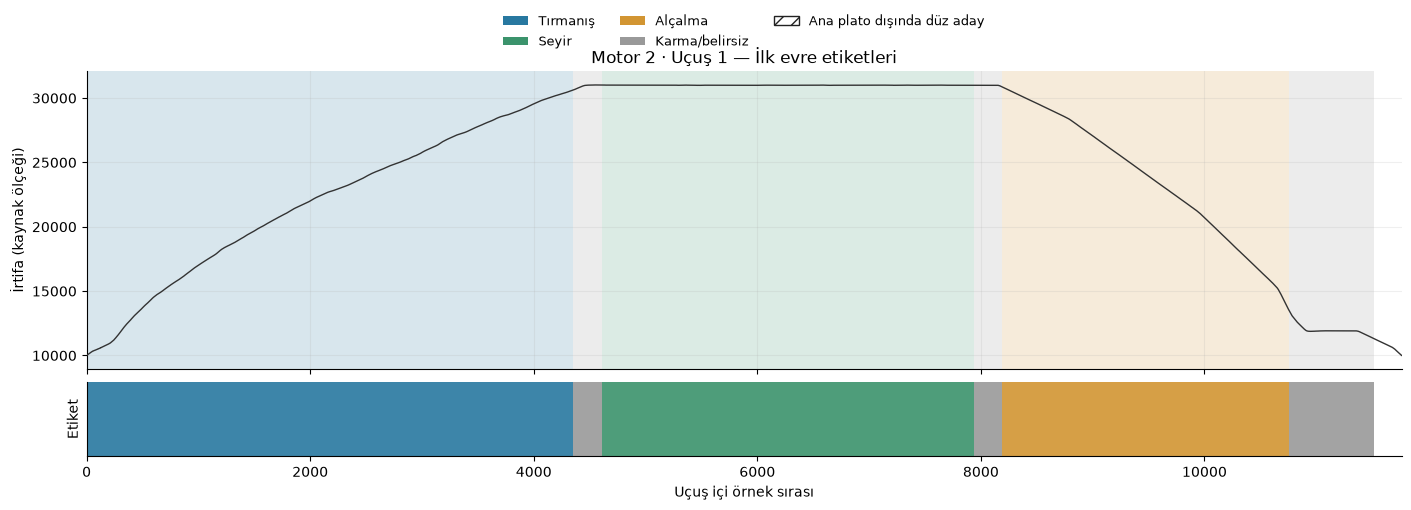

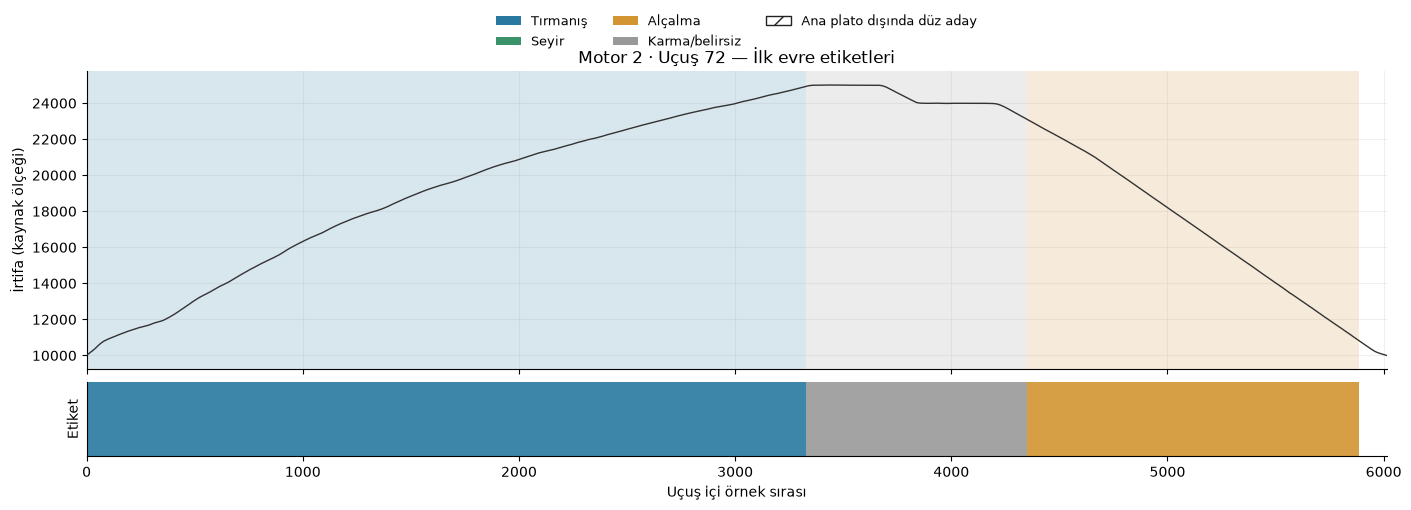

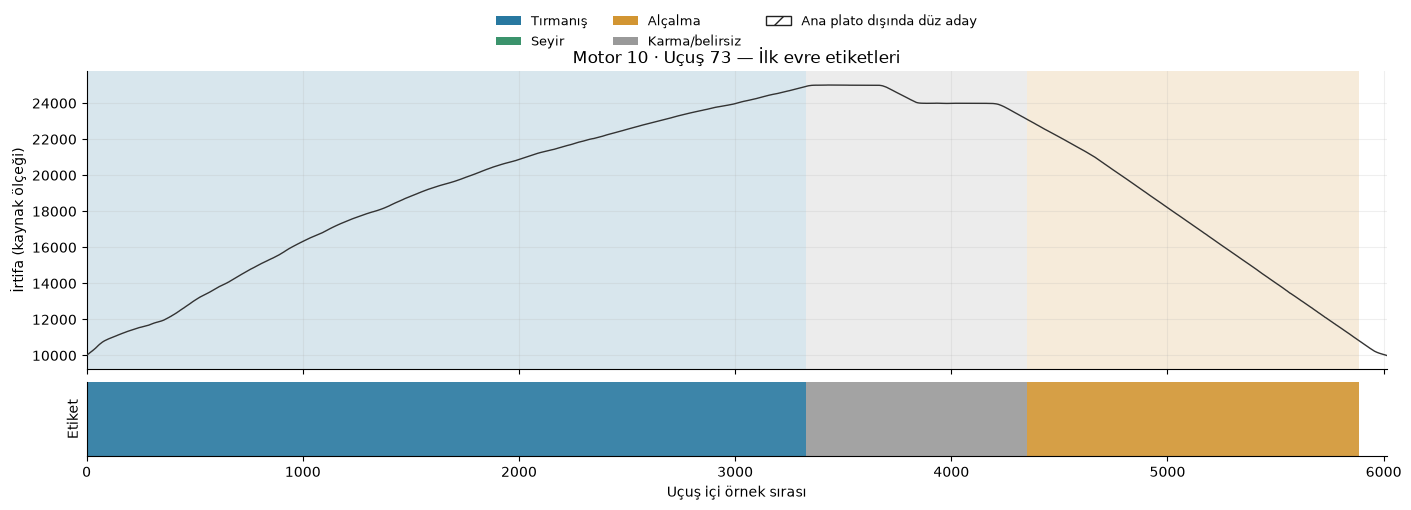

,Motor,Uçuş,Tırmanış,Seyir,Alçalma,Karma/belirsiz,Plato dışında düz aday,Pencere dışında kalan örnek
0,2,1,17,13,10,5,0,244
1,2,72,13,0,6,4,0,126
2,10,73,13,0,6,4,0,126


In [31]:
from matplotlib.patches import Patch

phase_colors = {
    "Tırmanış": "#2878A0",
    "Seyir": "#3B936C",
    "Alçalma": "#D29532",
    "Karma/belirsiz": "#999999",
}

no_plateau_flights = (
    plateau_summary.loc[
        plateau_summary["cruise_windows"].eq(0),
        ["unit", "cycle"],
    ]
    .sort_values(["unit", "cycle"])
)

print("Ana seyir platosu seçilemeyen uçuşlar:")
display(no_plateau_flights.reset_index(drop=True))

flights_to_check = list(dict.fromkeys(
    [(2, 1)]
    + [
        (int(row.unit), int(row.cycle))
        for row in no_plateau_flights.itertuples(index=False)
    ]
))

flight_lookup = flight_catalog.set_index(["unit", "cycle"])
check_rows = []

with h5py.File(HDF5_PATH, mode="r") as h5:
    altitude_index = decode_names(h5["W_var"]).index("alt")

    for unit, cycle in flights_to_check:
        flight = flight_lookup.loc[(unit, cycle)]
        flight_start = int(flight["start_row"])
        flight_end = int(flight["end_row"])

        altitude = h5["W_dev"][
            flight_start:flight_end, altitude_index
        ]
        assert np.isfinite(altitude).all()

        windows = (
            phase_labels.loc[
                phase_labels["unit"].eq(unit)
                & phase_labels["cycle"].eq(cycle)
            ]
            .sort_values("start_row")
        )
        assert not windows.empty

        fig, (profile_ax, label_ax) = plt.subplots(
            2, 1,
            figsize=(14, 5),
            sharex=True,
            gridspec_kw={"height_ratios": [4, 1]},
            constrained_layout=True,
        )

        profile_ax.plot(
            np.arange(len(altitude)),
            altitude,
            color="#333333",
            linewidth=1,
            zorder=3,
        )

        for window in windows.itertuples(index=False):
            start = int(window.start_row)
            end = int(window.end_row)

            assert flight_start <= start < end <= flight_end

            local_start = start - flight_start
            local_end = end - flight_start
            color = phase_colors[window.phase]

            profile_ax.axvspan(
                local_start, local_end,
                color=color, alpha=0.18, linewidth=0,
            )
            label_ax.axvspan(
                local_start, local_end,
                color=color, alpha=0.9, linewidth=0,
            )

            if (
                window.local_behavior == "düz aday"
                and not window.main_plateau
            ):
                label_ax.axvspan(
                    local_start, local_end,
                    facecolor="none",
                    edgecolor="#222222",
                    linewidth=0.7,
                    hatch="//",
                )

        profile_ax.set(
            title=f"Motor {unit} · Uçuş {cycle} — İlk evre etiketleri",
            ylabel="İrtifa (kaynak ölçeği)",
        )
        profile_ax.grid(alpha=0.2)
        profile_ax.ticklabel_format(
            axis="y", style="plain", useOffset=False
        )

        label_ax.set(
            xlabel="Uçuş içi örnek sırası",
            ylabel="Etiket",
            yticks=[],
            xlim=(0, len(altitude)),
        )

        for ax in (profile_ax, label_ax):
            ax.spines[["top", "right"]].set_visible(False)

        legend_handles = [
            Patch(facecolor=color, label=phase)
            for phase, color in phase_colors.items()
        ]
        legend_handles.append(
            Patch(
                facecolor="white",
                edgecolor="#222222",
                hatch="//",
                label="Ana plato dışında düz aday",
            )
        )
        profile_ax.legend(
            handles=legend_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.23),
            ncol=3,
            frameon=False,
            fontsize=9,
        )

        plt.show()

        counts = windows["phase"].value_counts()
        covered_samples = int(
            (windows["end_row"] - windows["start_row"]).sum()
        )

        check_rows.append({
            "Motor": unit,
            "Uçuş": cycle,
            **{
                phase: int(counts.get(phase, 0))
                for phase in PHASE_ORDER
            },
            "Plato dışında düz aday": int(
                (
                    windows["local_behavior"].eq("düz aday")
                    & ~windows["main_plateau"]
                ).sum()
            ),
            "Pencere dışında kalan örnek": (
                len(altitude) - covered_samples
            ),
        })

display(pd.DataFrame(check_rows))

## Görsel Kontrol Sonucu ve Validation Tahminleriyle Eşleştirme

Motor 2–Uçuş 1’de tırmanış, ana seyir platosu ve alçalma etiketleri
genel irtifa profiliyle uyumlu görünmektedir. Geçişlerin bir bölümü
karma/belirsiz olarak tutulmuştur.

Motor 2–Uçuş 72 ve Motor 10–Uçuş 73’te kısa düz bölgeler görülmesine
rağmen, mevcut pencere sınırları ve eğim koşulları altında düz aday
pencere bulunmamıştır. Bu uçuşlarda seyir etiketi atanmaması,
fiziksel olarak seyir olmadığı anlamına gelmez.

Bu kontrol sınırlı sayıda uçuşa aittir; bütün etiketlerin doğruluğunu
kanıtlamaz. İlk keşif yöntemi korunarak hata analizine geçilecektir.

### Eşleştirme kuralları

Uçuş evresi etiketleri, daha önce doğrulanan validation tahminlerine
`window_id` üzerinden bire bir bağlanacaktır.

- İki tabloda pencere kimlikleri benzersiz olmalıdır.
- Pencere kapsamları tamamen eşleşmelidir.
- Eşleşen kayıtların motor ve uçuş bilgileri aynı olmalıdır.
- Birleştirme sonrasında 20.339 pencerenin tamamı korunmalıdır.
- Tahminler, gerçek RUL değerleri ve fold bilgileri değişmemelidir.

Karma/belirsiz pencereler analizden çıkarılmayacaktır.

Sonraki metrikler pencere ağırlıklı olacaktır. Evre başına farklı
motor ve uçuş sayıları da raporlanarak, çok sayıda pencerenin
bağımsız uçuşlar anlamına gelmediği görünür tutulacaktır.

Evreler arasındaki hata farkları tek başına nedensellik göstermez;
RUL dağılımı ve motor bileşimi farklılıkları ayrıca incelenecektir.

In [35]:
label_columns = [
    "window_id", "unit", "cycle",
    "phase", "local_behavior", "main_plateau",
]

assert validation_predictions["window_id"].is_unique
assert phase_labels["window_id"].is_unique
assert phase_labels["phase"].notna().all()

assert set(validation_predictions["window_id"]) == set(
    phase_labels["window_id"]
), "Tahmin ve etiket tablolarının pencere kapsamları farklı."

phase_predictions = validation_predictions.merge(
    phase_labels[label_columns],
    on="window_id",
    how="outer",
    suffixes=("", "_label"),
    validate="one_to_one",
    indicator=True,
)

assert phase_predictions["_merge"].eq("both").all()
assert phase_predictions["unit"].eq(
    phase_predictions["unit_label"]
).all(), "Motor bilgileri uyuşmuyor."

assert phase_predictions["cycle"].eq(
    phase_predictions["cycle_label"]
).all(), "Uçuş bilgileri uyuşmuyor."

assert len(phase_predictions) == len(validation_predictions) == 20339
assert phase_predictions["phase"].notna().all()

phase_predictions = (
    phase_predictions
    .drop(columns=["unit_label", "cycle_label", "_merge"])
    .sort_values("window_id")
    .reset_index(drop=True)
)

# Tahmin tablosundaki bütün sütunların değişmeden korunduğunu doğrula.
pd.testing.assert_frame_equal(
    phase_predictions[validation_predictions.columns],
    validation_predictions
    .sort_values("window_id")
    .reset_index(drop=True),
)

# Uçuş kimliği motor ve cycle birlikte kullanılarak tanımlanır.
coverage = (
    phase_predictions.groupby("phase", observed=False)
    .agg(
        window_count=("window_id", "size"),
        motor_count=("unit", "nunique"),
    )
)

flight_counts = (
    phase_predictions[["phase", "unit", "cycle"]]
    .drop_duplicates()
    .groupby("phase", observed=False)
    .size()
)

coverage["flight_count"] = flight_counts
coverage = coverage.rename(columns={
    "window_count": "Pencere sayısı",
    "motor_count": "Motor sayısı",
    "flight_count": "Farklı uçuş sayısı",
})

assert coverage["Pencere sayısı"].sum() == len(phase_predictions)

print("Eşleştirme başarılı:", len(phase_predictions), "validation penceresi.")
print("Tahminler, RUL değerleri ve fold bilgileri korundu.")

display(coverage)

display(
    phase_predictions[
        [
            "window_id", "unit", "cycle", "fold",
            "actual_rul", "predicted_rul", "phase",
        ]
    ].head()
)

Eşleştirme başarılı: 20339 validation penceresi.
Tahminler, RUL değerleri ve fold bilgileri korundu.


,Pencere sayısı,Motor sayısı,Farklı uçuş sayısı
phase,,,
Tırmanış,5992,6,446
Seyir,5014,6,444
Alçalma,3914,6,446
Karma/belirsiz,5419,6,438


,window_id,unit,cycle,fold,actual_rul,predicted_rul,phase
0,0,2,1,1,74.0,58.339378,Tırmanış
1,1,2,1,1,74.0,56.798862,Tırmanış
2,2,2,1,1,74.0,57.320042,Tırmanış
3,3,2,1,1,74.0,58.363407,Tırmanış
4,4,2,1,1,74.0,59.329769,Tırmanış


## Uçuş Evrelerine Göre Validation Tahmin Hataları

Uçuş evresi etiketleri, 20.339 validation tahminiyle pencere kimliği
üzerinden bire bir eşleştirilmiştir. Motor ve uçuş bilgileri doğrulanmış,
tahminler ve gerçek RUL etiketleri korunmuştur.

Her evre için şu değerler hesaplanacaktır:

- Pencere sayısı
- Farklı motor ve uçuş sayısı
- MAE: mutlak hataların ortalaması
- RMSE: kare hataların ortalamasının karekökü
- Bias: tahmin edilen RUL − gerçek RUL farkının ortalaması

Pozitif Bias ortalamada fazla, negatif Bias eksik RUL tahminini gösterir.
Hata metriklerinin birimi uçuş döngüsüdür.

### Yorumlama sınırları

Her pencere eşit ağırlıktadır. Aynı uçuşa ait pencereler bağımsız
gözlemler değildir; uzun uçuşlar daha fazla pencereyle temsil edilebilir.

Karma/belirsiz pencereler ayrı bir grup olarak korunacaktır.
Bu grup hem geçişleri hem de yöntemle güvenle sınıflandırılamayan
bölümleri içerebilir.

Genel evre tablosu bütün RUL değerlerini birlikte değerlendirecektir.
Evreler arasındaki hata farkları RUL dağılımı ve motor bileşiminden
etkilenebilir; doğrudan uçuş evresinin neden olduğu farklar olarak
yorumlanmayacaktır.

Ardından aynı metrikler RUL aralıklarına göre ayrılacak ve özellikle
61 ve üzerindeki pencereler motor bazında incelenecektir.

In [36]:
# Hataları mevcut validation tahminlerinden hesapla.
phase_errors = phase_predictions.assign(
    error=(
        phase_predictions["predicted_rul"]
        - phase_predictions["actual_rul"]
    )
)
phase_errors["absolute_error"] = phase_errors["error"].abs()
phase_errors["squared_error"] = phase_errors["error"].pow(2)

assert np.isfinite(
    phase_errors[["error", "absolute_error", "squared_error"]]
).all().all()

phase_metrics = (
    phase_errors.groupby("phase", observed=False)
    .agg(
        window_count=("window_id", "size"),
        motor_count=("unit", "nunique"),
        mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"),
        bias=("error", "mean"),
    )
)

# Uçuş kimliği: motor ve cycle birlikte.
phase_metrics["flight_count"] = (
    phase_errors[["phase", "unit", "cycle"]]
    .drop_duplicates()
    .groupby("phase", observed=False)
    .size()
)

phase_metrics["rmse"] = np.sqrt(phase_metrics["mse"])

phase_metrics = (
    phase_metrics[
        ["window_count", "motor_count", "flight_count", "mae", "rmse", "bias"]
    ]
    .reindex(PHASE_ORDER)
    .rename(columns={
        "window_count": "Pencere sayısı",
        "motor_count": "Motor sayısı",
        "flight_count": "Farklı uçuş sayısı",
        "mae": "MAE",
        "rmse": "RMSE",
        "bias": "Bias",
    })
    .rename_axis("Uçuş evresi")
)

assert phase_metrics["Pencere sayısı"].sum() == len(phase_predictions)

display(
    phase_metrics.style.format(
        {
            "Pencere sayısı": "{:d}",
            "Motor sayısı": "{:d}",
            "Farklı uçuş sayısı": "{:d}",
            "MAE": "{:.4f}",
            "RMSE": "{:.4f}",
            "Bias": "{:+.4f}",
        },
        na_rep="—",
    )
)

print("Değerlendirilen toplam pencere:", len(phase_predictions))

,Pencere sayısı,Motor sayısı,Farklı uçuş sayısı,MAE,RMSE,Bias
Uçuş evresi,,,,,,
Tırmanış,5992,6,446,3.4898,5.2715,-0.8682
Seyir,5014,6,444,3.0872,4.7618,-0.0258
Alçalma,3914,6,446,4.0651,5.8727,-0.4127
Karma/belirsiz,5419,6,438,3.3955,4.9494,-0.0261


Değerlendirilen toplam pencere: 20339


## Genel Evre Sonuçları ve RUL Aralıklarına Geçiş

Bütün validation pencereleri birlikte değerlendirildiğinde:

- Alçalma grubunda en yüksek MAE (4,0651) ve RMSE (5,8727) görülmektedir.
- Seyir grubunda en düşük MAE (3,0872) ve RMSE (4,7618) görülmektedir.
- Tırmanış grubunun Bias değeri −0,8682 ile ortalamada eksik tahmine işaret eder.
- Seyir ve karma/belirsiz gruplarında ortalama işaretli hata sıfıra yakındır.
  Bu durum, pozitif ve negatif hataların birbirini dengelemesinden kaynaklanabilir.

Bu sonuçlar ilk keşif amaçlı evre etiketlerine dayanır.
Genel tablo, yüksek RUL’daki hataların hangi evrede yoğunlaştığını
tek başına göstermez.

### Sonraki analiz: RUL aralığı × uçuş evresi

Gerçek RUL değerleri 0–20, 21–40, 41–60 ve 61 ve üzeri olarak
gruplandırılacak; her aralık–evre çifti için pencere sayısı,
farklı motor ve uçuş sayısı, MAE, RMSE ve Bias hesaplanacaktır.

Toplam 16 grup gösterilecektir. Boş gruplarda pencere sayısı 0,
hata metrikleri ise hesaplanamaz olarak belirtilecektir.

RUL aralıklarına ayırmak karşılaştırmayı ayrıntılandırır; ancak aynı
aralık içindeki gerçek RUL dağılımları ve motor katkıları yine farklı
olabilir. Sonuçlar nedensel etki olarak yorumlanmayacaktır.

In [37]:
RUL_LABELS = ["0–20", "21–40", "41–60", "61 ve üzeri"]

rul_phase_data = phase_errors.copy()

assert rul_phase_data["actual_rul"].ge(0).all()
assert rul_phase_data["actual_rul"].mod(1).eq(0).all()

rul_phase_data["rul_group"] = pd.cut(
    rul_phase_data["actual_rul"],
    bins=[0, 20, 40, 60, np.inf],
    labels=RUL_LABELS,
    include_lowest=True,
    right=True,
    ordered=True,
)

assert rul_phase_data["rul_group"].notna().all()
assert rul_phase_data["phase"].notna().all()

group_columns = ["rul_group", "phase"]

# Bütün RUL–evre çiftlerini, boş olanlar dahil, göster.
full_index = pd.MultiIndex.from_product(
    [RUL_LABELS, PHASE_ORDER],
    names=group_columns,
)

rul_phase_metrics = (
    rul_phase_data
    .groupby(group_columns, observed=True)
    .agg(
        window_count=("window_id", "size"),
        motor_count=("unit", "nunique"),
        mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"),
        bias=("error", "mean"),
    )
    .reindex(full_index)
)

flight_counts = (
    rul_phase_data[
        ["rul_group", "phase", "unit", "cycle"]
    ]
    .drop_duplicates()
    .groupby(group_columns, observed=True)
    .size()
)

rul_phase_metrics["flight_count"] = flight_counts.reindex(full_index)

count_columns = ["window_count", "motor_count", "flight_count"]
rul_phase_metrics[count_columns] = (
    rul_phase_metrics[count_columns].fillna(0).astype(int)
)

rul_phase_metrics["rmse"] = np.sqrt(rul_phase_metrics["mse"])

rul_phase_metrics = (
    rul_phase_metrics[
        ["window_count", "motor_count", "flight_count", "mae", "rmse", "bias"]
    ]
    .rename(columns={
        "window_count": "Pencere sayısı",
        "motor_count": "Motor sayısı",
        "flight_count": "Farklı uçuş sayısı",
        "mae": "MAE",
        "rmse": "RMSE",
        "bias": "Bias",
    })
    .rename_axis(index=["Gerçek RUL aralığı", "Uçuş evresi"])
)

assert len(rul_phase_metrics) == 16
assert rul_phase_metrics["Pencere sayısı"].sum() == len(rul_phase_data)

display(
    rul_phase_metrics.style.format(
        {
            "Pencere sayısı": "{:d}",
            "Motor sayısı": "{:d}",
            "Farklı uçuş sayısı": "{:d}",
            "MAE": "{:.4f}",
            "RMSE": "{:.4f}",
            "Bias": "{:+.4f}",
        },
        na_rep="—",
    )
)

print("Toplam pencere:", rul_phase_metrics["Pencere sayısı"].sum())

Toplam pencere: 20339


## Son Analiz: Motor Bazında Yüksek RUL × Uçuş Evresi

Gerçek RUL ≥61 olan validation pencereleri birlikte değerlendirildiğinde:

- Alçalma: MAE 8,5530; RMSE 10,2250; Bias −8,1485.
- Tırmanış: MAE 7,9263; RMSE 9,7069; Bias −7,2719.
- Seyir: MAE 5,9471; RMSE 7,5989; Bias −4,5771.
- Karma/belirsiz: MAE 6,2846; RMSE 7,9683; Bias −4,8453.

Bu birleşik sonuçlarda alçalma ve tırmanış gruplarında hata daha
yüksektir. Ancak bunun bütün motorlarda geçerli olup olmadığı
henüz bilinmemektedir.

### Karşılaştırma

Yalnızca gerçek RUL ≥61 olan pencereler kullanılarak her motor
ve uçuş evresi için şu değerler hesaplanacaktır:

- Pencere sayısı
- Farklı uçuş sayısı
- MAE
- RMSE
- Bias

Altı motor ve dört evreden oluşan 24 grup gösterilecektir.
Boş gruplarda sayılar 0, hata metrikleri ise hesaplanamaz olacaktır.
Karma/belirsiz pencereler korunacaktır.

### Değerlendirme amacı ve sınırları

Alçalma ve tırmanıştaki yüksek hatanın motorlar arasında ne kadar
tutarlı olduğu ve eksik tahmin eğiliminin hangi motorlarda
görüldüğü incelenecektir.

Her motor kendi LOEO fold’unun validation tahminleriyle değerlendirilir.
Metrikler pencere ağırlıklıdır; aynı uçuşun pencereleri bağımsız değildir.
Motorların yüksek RUL kapsamları ve evre başına örnek sayıları farklıdır.

Sonuçlar keşif amaçlı evre etiketlerine dayanır. Evre ile hata
arasındaki ilişki, doğrudan nedensel etki olarak yorumlanmayacaktır.
Bu karşılaştırmanın ardından temel bulgular ve yöntem sınırları
özetlenerek analiz tamamlanacaktır.

In [38]:
high_rul_data = phase_errors.loc[
    phase_errors["actual_rul"].ge(61)
].copy()

assert not high_rul_data.empty
assert high_rul_data["window_id"].is_unique
assert high_rul_data["phase"].notna().all()

motors = sorted(phase_errors["unit"].unique())
group_columns = ["unit", "phase"]

full_index = pd.MultiIndex.from_product(
    [motors, PHASE_ORDER],
    names=group_columns,
)

high_rul_motor_metrics = (
    high_rul_data
    .groupby(group_columns, observed=True)
    .agg(
        window_count=("window_id", "size"),
        flight_count=("cycle", "nunique"),
        mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"),
        bias=("error", "mean"),
    )
    .reindex(full_index)
)

count_columns = ["window_count", "flight_count"]
high_rul_motor_metrics[count_columns] = (
    high_rul_motor_metrics[count_columns]
    .fillna(0)
    .astype(int)
)

high_rul_motor_metrics["rmse"] = np.sqrt(
    high_rul_motor_metrics["mse"]
)

high_rul_motor_metrics = (
    high_rul_motor_metrics[
        ["window_count", "flight_count", "mae", "rmse", "bias"]
    ]
    .rename(columns={
        "window_count": "Pencere sayısı",
        "flight_count": "Farklı uçuş sayısı",
        "mae": "MAE",
        "rmse": "RMSE",
        "bias": "Bias",
    })
    .rename_axis(index=["Motor", "Uçuş evresi"])
)

assert len(high_rul_motor_metrics) == 24
assert (
    high_rul_motor_metrics["Pencere sayısı"].sum()
    == len(high_rul_data)
)

# Her motorun bütün yüksek RUL pencereleri korunmuş olmalı.
expected_counts = high_rul_data.groupby("unit").size().reindex(
    motors, fill_value=0
)
actual_counts = (
    high_rul_motor_metrics["Pencere sayısı"]
    .groupby(level="Motor")
    .sum()
    .reindex(motors)
)

np.testing.assert_array_equal(
    actual_counts.to_numpy(),
    expected_counts.to_numpy(),
)

display(
    high_rul_motor_metrics.style.format(
        {
            "Pencere sayısı": "{:d}",
            "Farklı uçuş sayısı": "{:d}",
            "MAE": "{:.4f}",
            "RMSE": "{:.4f}",
            "Bias": "{:+.4f}",
        },
        na_rep="—",
    )
)

print("Yüksek RUL pencere sayısı:", len(high_rul_data))
print(
    "Yüksek RUL içeren farklı uçuş sayısı:",
    high_rul_data[["unit", "cycle"]].drop_duplicates().shape[0],
)
print("Motor bazındaki pencere kapsamı doğrulandı.")

Yüksek RUL pencere sayısı: 3734
Yüksek RUL içeren farklı uçuş sayısı: 80
Motor bazındaki pencere kapsamı doğrulandı.


## Sonuç: Yüksek RUL Tahmin Hataları ve Uçuş Evreleri

Bu analiz, Window=256, Stride=256, learning_rate=0.001 ve seed=42
ayarlarıyla eğitilen TCN modelinin altı LOEO fold’una ait mevcut
validation tahminleri üzerinde gerçekleştirilmiştir.

### Temel bulgular

Gerçek RUL ≥61 grubunda 3.734 pencere ve 80 farklı uçuş bulunmaktadır.

Birleşik sonuçlarda en yüksek MAE ve RMSE alçalma grubunda,
ardından tırmanış grubunda görülmektedir. Ancak motor bazında
evre sıralaması aynı değildir:

| Motor | En yüksek MAE/RMSE görülen evre | MAE | RMSE |
|---|---|---:|---:|
| 2 | Alçalma | 8,8796 | 10,7621 |
| 5 | Tırmanış | 11,4696 | 13,2870 |
| 10 | Alçalma | 9,2760 | 10,4898 |
| 16 | Tırmanış | 6,2245 | 6,3599 |
| 18 | Alçalma | 5,3730 | 6,1737 |
| 20 | Alçalma | 7,4703 | 8,3723 |

### Hata yönü

Motor 2, 5, 10, 16 ve 18’de yüksek RUL grubunun bütün evrelerinde
Bias negatiftir: model kalan ömrü ortalamada eksik tahmin etmektedir.

Motor 20’de ise yön evreye bağlıdır:

- Tırmanış: Bias +4,1973
- Seyir: Bias +2,8425
- Alçalma: Bias −7,4703
- Karma/belirsiz: Bias +1,8828

Dolayısıyla motorun toplam Bias değeri, farklı evrelerdeki zıt
yönlü hataları gizleyebilir.

### Araştırma sorusuna yanıt

Bu validation sonuçlarında yüksek RUL tahmin hataları ile
irtifa profilinden türetilen uçuş evreleri arasında betimsel
bir ilişki görülmektedir. Alçalma dört motorda, tırmanış iki
motorda en yüksek hata grubudur.

Bulgular, yüksek RUL hatalarının yalnızca tek bir uçuş evresine
özgü olduğunu veya uçuş evresinin hataya doğrudan neden olduğunu
göstermemektedir.

### Yöntem ve yorum sınırları

- Evre etiketleri dört adet 64 örneklik bölüm eğimi, 0.3 aday
  toleransı ve ana plato seçimiyle oluşturulan keşif amaçlı etiketlerdir.
  Resmî uçuş evresi etiketleriyle doğrulanmamıştır.
- Karma/belirsiz pencereler korunmuştur; bu grup yalnızca gerçek
  evre geçişlerinden oluşmaz.
- Metrikler pencere ağırlıklıdır. Aynı uçuşun pencereleri bağımsız
  gözlemler değildir.
- Motor 16’nın yüksek RUL sonuçları yalnızca 2, Motor 20’ninkiler
  5 uçuşa dayanır; bu sonuçların genellenebilirliği sınırlıdır.
- Motorların gerçek RUL kapsamları, uçuş profilleri ve evre başına
  pencere sayıları farklıdır. Her motor farklı bir LOEO modeliyle
  değerlendirilmiştir.
- Eşik duyarlılığı ve istatistiksel belirsizlik bu ilk analizde
  tamamlanmamıştır. Bulgular anlamlılık veya nedensellik iddiası taşımaz.
- Eğitim yeniden yapılmamış; model tahminleri, RUL etiketleri ve
  preprocessing dosyaları değiştirilmemiştir.

Bu aşamada planlanan genel, RUL aralığına göre ve yüksek RUL’da
motor bazlı uçuş evresi hata analizleri tamamlanmıştır.